In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("C:/Users/jsmvk/Desktop/SGH/Praca magisterska/south+german+credit+update/SouthGermanCredit.asc", sep = " ", engine = "python")

[Text(0, 0, '300'), Text(0, 0, '700')]

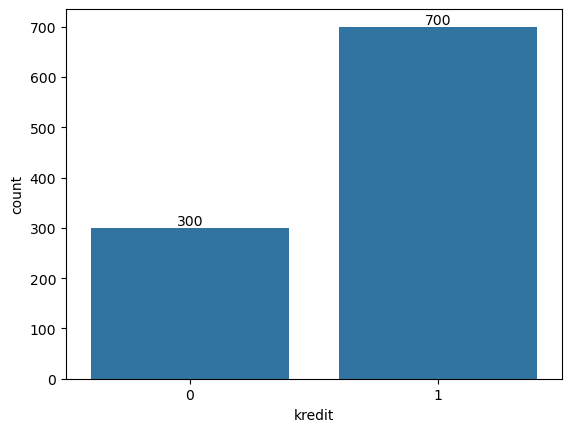

In [2]:
ax = sns.countplot(data = df, x = 'kredit')
ax.bar_label(ax.containers[0])

In [3]:
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import Metadata

In [4]:
#metadata = Metadata.detect_from_dataframe(df)

#synthesizer = GaussianCopulaSynthesizer(metadata)
#synthesizer.fit(df[df["kredit"] == 0])

#synthetic_data_0 = synthesizer.sample(num_rows = 400)
#synthetic_data_0.to_excel('C:/Users/jsmvk/Desktop/SGH/Praca magisterska/synthetic_data.xlsx', index=False)

In [5]:
synthetic_data_0 = pd.read_excel("C:/Users/jsmvk/Desktop/SGH/Praca magisterska/synthetic_data.xlsx", engine = 'openpyxl')

In [6]:
len(synthetic_data_0[synthetic_data_0["kredit"] == 0])

400

In [7]:
df = pd.concat([synthetic_data_0, df], axis = 0)

In [8]:
df = df.sample(frac = 1).reset_index(drop = True)

In [9]:
mapping_colnames = {
    
    "laufkont":"stan_konta",
    "laufzeit":"czas_zapadalności_kredytu",
    "moral":"historia_kredytowa",
    "verw":"cel_kredytu",
    "hoehe":"wielkość_kredytu",
    "sparkont":"oszczędności",
    "beszeit":"czas_zatrudnienia",
    "rate":"wysokość_raty_kredytu",
    "famges":"status_matrymonialny",
    "buerge":"inni_kredytobiorcy",
    "wohnzeit":"miejsce_zamieszkania",
    "verm":"najdroższa_własność",
    "alter":"wiek",
    "weitkred":"inne_kredyty",
    "wohn":"sposób_opłaty_mieszkania",
    "bishkred":"liczba_kredytów_w_historii",
    "beruf":"praca",
    "pers":"liczba_osób_na_utrzymaniu",
    "telef":"telefon",
    "gastarb":"cudzoziemiec",
    "kredit":"ryzyko_kredytowe"
    
}

In [10]:
df.rename(columns = mapping_colnames, inplace = True)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   stan_konta                  1400 non-null   int64
 1   czas_zapadalności_kredytu   1400 non-null   int64
 2   historia_kredytowa          1400 non-null   int64
 3   cel_kredytu                 1400 non-null   int64
 4   wielkość_kredytu            1400 non-null   int64
 5   oszczędności                1400 non-null   int64
 6   czas_zatrudnienia           1400 non-null   int64
 7   wysokość_raty_kredytu       1400 non-null   int64
 8   status_matrymonialny        1400 non-null   int64
 9   inni_kredytobiorcy          1400 non-null   int64
 10  miejsce_zamieszkania        1400 non-null   int64
 11  najdroższa_własność         1400 non-null   int64
 12  wiek                        1400 non-null   int64
 13  inne_kredyty                1400 non-null   int64
 14  sposób_opłaty_miesz

In [12]:
df['cel_kredytu'].unique()

array([ 0,  2,  9,  1,  3,  5,  6,  8, 10,  4])

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   stan_konta                  1400 non-null   int64
 1   czas_zapadalności_kredytu   1400 non-null   int64
 2   historia_kredytowa          1400 non-null   int64
 3   cel_kredytu                 1400 non-null   int64
 4   wielkość_kredytu            1400 non-null   int64
 5   oszczędności                1400 non-null   int64
 6   czas_zatrudnienia           1400 non-null   int64
 7   wysokość_raty_kredytu       1400 non-null   int64
 8   status_matrymonialny        1400 non-null   int64
 9   inni_kredytobiorcy          1400 non-null   int64
 10  miejsce_zamieszkania        1400 non-null   int64
 11  najdroższa_własność         1400 non-null   int64
 12  wiek                        1400 non-null   int64
 13  inne_kredyty                1400 non-null   int64
 14  sposób_opłaty_miesz

In [14]:
#mapping_colnames = dict(np.array(credit_approval.variables[["name", "description"]]))

In [15]:
#df.rename(columns = mapping_colnames, inplace = True)
#df.rename(columns = {'1 = Good, 0 = Bad' : 'class'}, inplace = True)

In [16]:
#df.info()

In [17]:
df.describe(exclude = "object")

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe
count,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,...,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000
mean,2.397143,22.181429,2.427857,2.903571,3479.517857,1.992143,3.353571,3.005000,2.652143,1.135000,...,2.438571,34.568571,2.634286,1.923571,1.393571,2.908571,1.854286,1.379286,1.970000,0.500000
std,1.244628,12.411399,1.086901,2.899062,2999.275355,1.526257,1.212274,1.120019,0.726105,0.453314,...,1.050109,11.501606,0.735476,0.561336,0.578469,0.663722,0.352946,0.485383,0.170648,0.500179
min,1.000000,4.000000,0.000000,0.000000,250.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,19.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,12.000000,2.000000,0.000000,1364.000000,1.000000,3.000000,2.000000,2.000000,1.000000,...,1.000000,26.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000
50%,2.000000,19.000000,2.000000,2.000000,2440.000000,1.000000,3.000000,3.000000,3.000000,1.000000,...,3.000000,32.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.500000
75%,4.000000,29.000000,3.250000,3.000000,4493.000000,3.000000,4.000000,4.000000,3.000000,1.000000,...,3.000000,40.250000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000
max,4.000000,72.000000,4.000000,10.000000,18424.000000,5.000000,5.000000,4.000000,4.000000,3.000000,...,4.000000,75.000000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000


In [18]:
def describe_advanced(data):
    
    data = np.asarray(data)
    
    return {
        "max": np.max(data),
        "min": np.min(data),
        "dominanta": stats.mode(data).mode[0],
        "kurtoza": np.round(stats.kurtosis(data), 2),
        "skośność": np.round(stats.skew(data), 2),
        "średnia": np.round(np.mean(data), 2),
        "odchylenie standardowe": np.round(np.std(data), 2),
        "współczynnik zmienności": np.round(np.round(np.std(data), 2) / np.round(np.mean(data), 2), 2)
    }

In [19]:
num_cols = ['czas_zapadalności_kredytu', 'wielkość_kredytu', 'wiek']

In [20]:
cat_cols = []

for i in df.columns:
    if i not in num_cols:
        cat_cols.append(i)

In [21]:
cat_cols.remove("ryzyko_kredytowe")
df[cat_cols] = df[cat_cols].astype("object")

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1400 non-null   object
 1   czas_zapadalności_kredytu   1400 non-null   int64 
 2   historia_kredytowa          1400 non-null   object
 3   cel_kredytu                 1400 non-null   object
 4   wielkość_kredytu            1400 non-null   int64 
 5   oszczędności                1400 non-null   object
 6   czas_zatrudnienia           1400 non-null   object
 7   wysokość_raty_kredytu       1400 non-null   object
 8   status_matrymonialny        1400 non-null   object
 9   inni_kredytobiorcy          1400 non-null   object
 10  miejsce_zamieszkania        1400 non-null   object
 11  najdroższa_własność         1400 non-null   object
 12  wiek                        1400 non-null   int64 
 13  inne_kredyty                1400 non-null   object
 14  spo

[Text(0, 0, '700'), Text(0, 0, '700')]

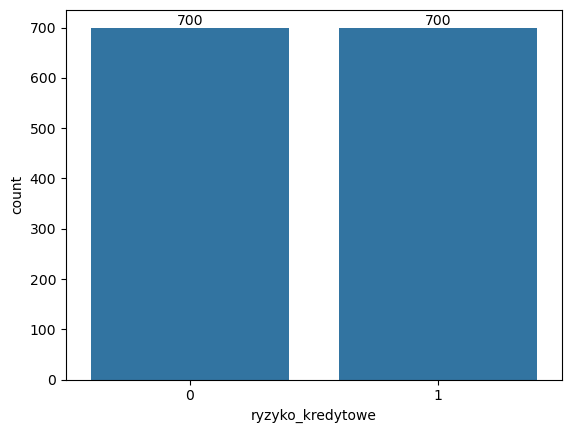

In [23]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [24]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(df[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [25]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,72,4,24,[0.67],[1.01],22.18,12.41,0.56
wielkość_kredytu,18424,250,458,[3.1],[1.73],3479.52,2998.20,0.86
wiek,75,19,23,[0.65],[1.05],34.57,11.50,0.33


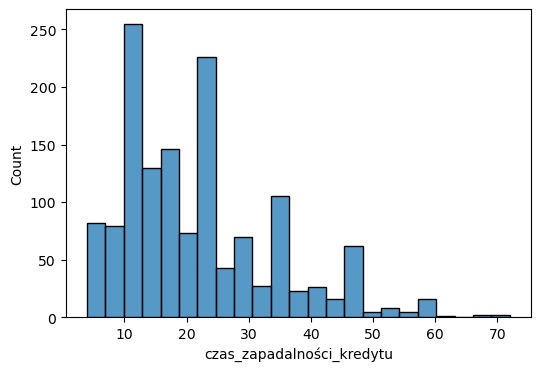

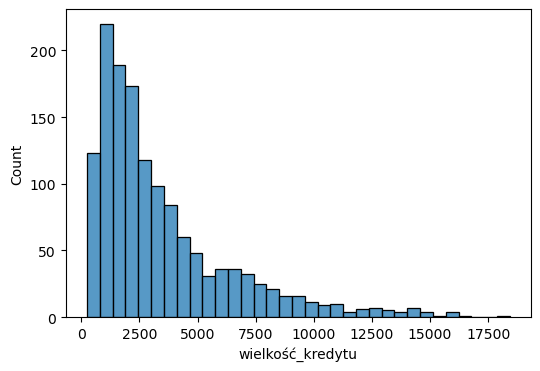

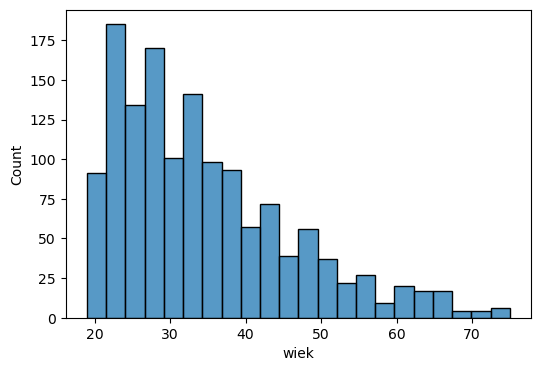

In [26]:
for i in num_cols:
     plt.figure(figsize=(6, 4))
     histograms = sns.histplot(df[i])
     plt.show()

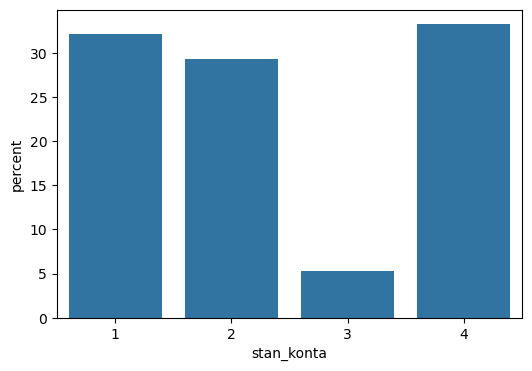

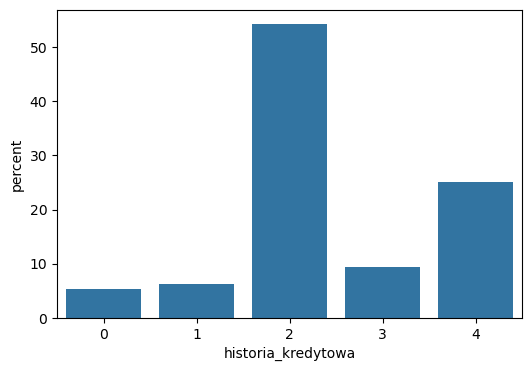

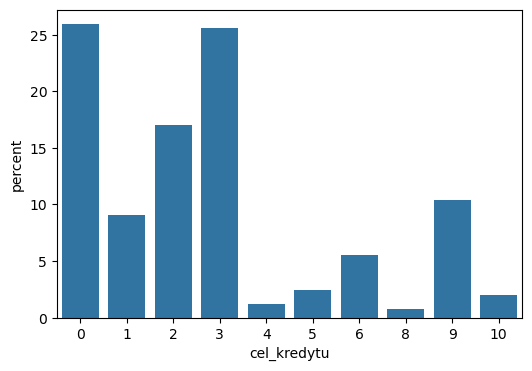

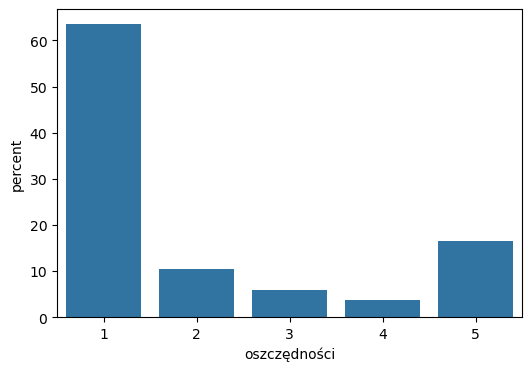

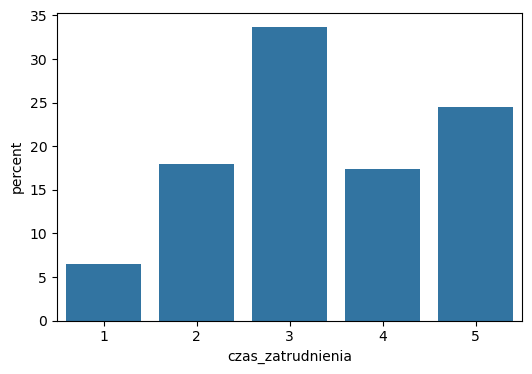

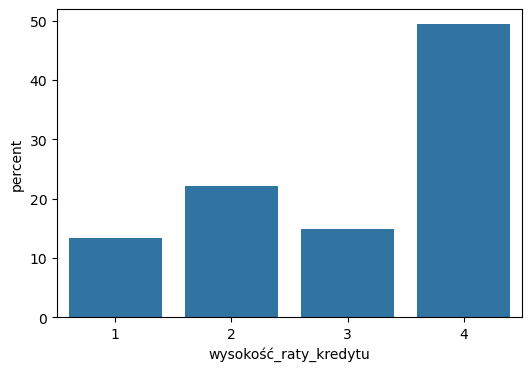

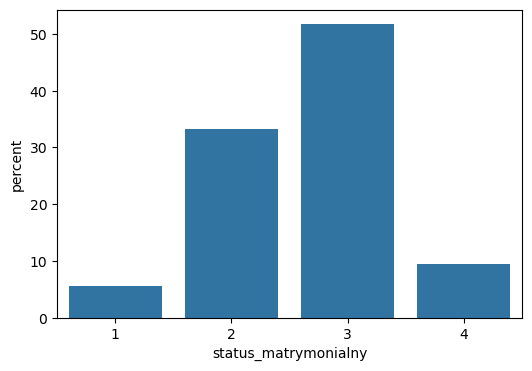

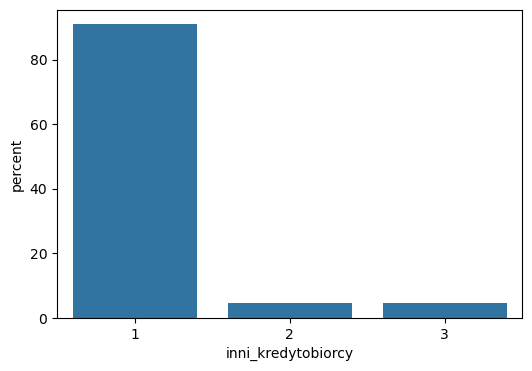

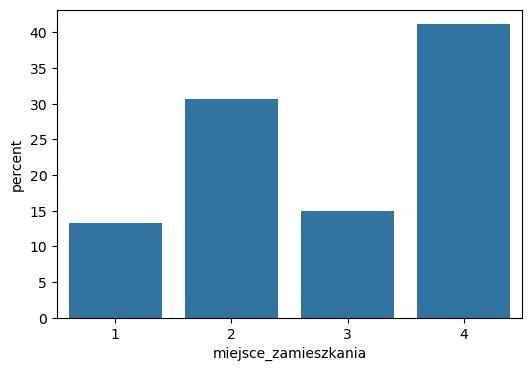

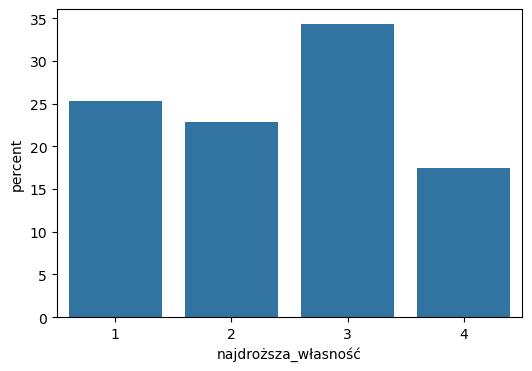

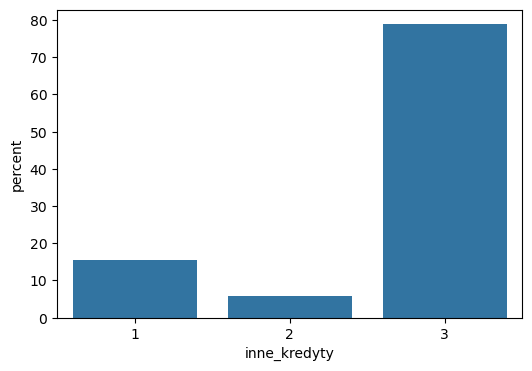

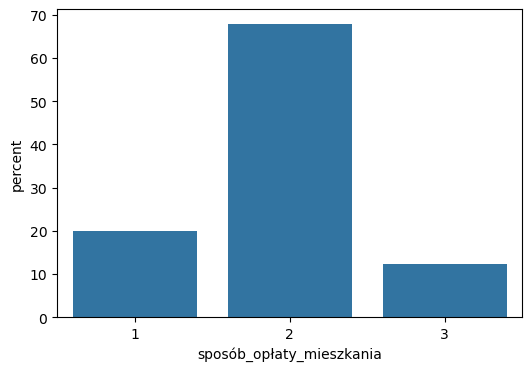

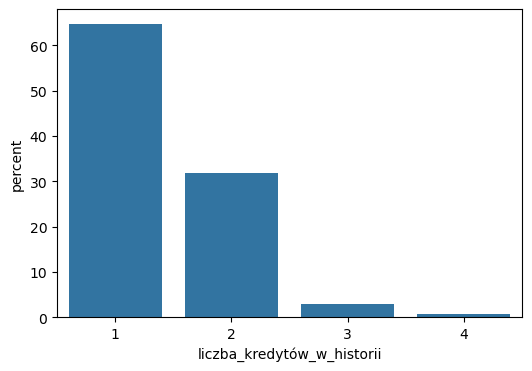

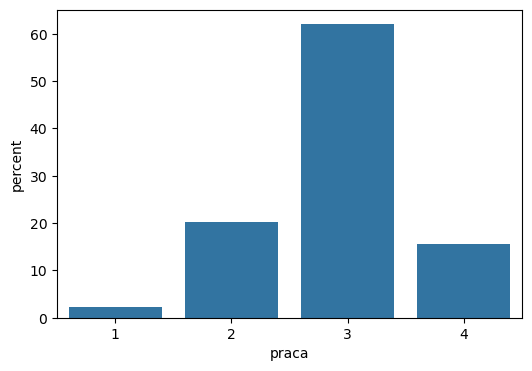

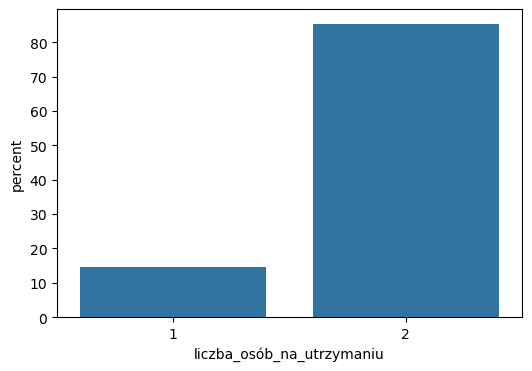

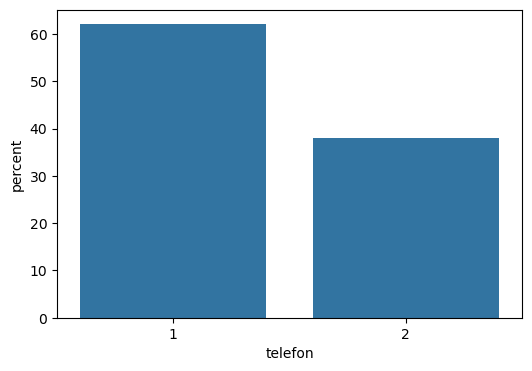

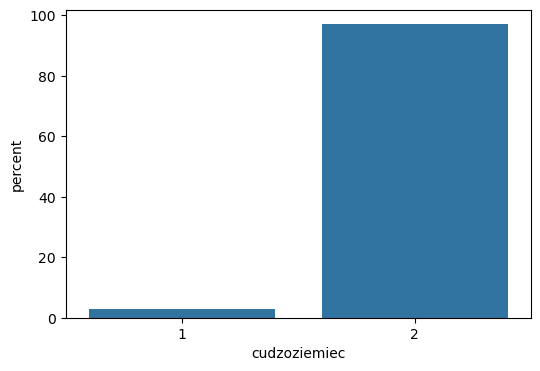

In [27]:
for i in cat_cols:
     plt.figure(figsize=(6, 4))
     countplots = sns.countplot(x = df[i], stat = "percent")
     plt.show()

In [28]:
scores = []

for i in cat_cols:
        name = i
        percent = df[i].value_counts() / len(df) * 100
        
        for category, percent in percent.items():
            scores.append({
                "Variable" : i,
                "Category": category,
                "Percent": percent
            })

In [29]:
scores = pd.DataFrame(scores)

In [30]:
scores.set_index("Variable", inplace = True)

In [31]:
scores.sort_values(by = ["Variable", "Category"], inplace = True)

In [32]:
print(scores.to_string())

                            Category    Percent
Variable                                       
cel_kredytu                        0  25.928571
cel_kredytu                        1   9.071429
cel_kredytu                        2  17.000000
cel_kredytu                        3  25.571429
cel_kredytu                        4   1.214286
cel_kredytu                        5   2.428571
cel_kredytu                        6   5.571429
cel_kredytu                        8   0.785714
cel_kredytu                        9  10.428571
cel_kredytu                       10   2.000000
cudzoziemiec                       1   3.000000
cudzoziemiec                       2  97.000000
czas_zatrudnienia                  1   6.500000
czas_zatrudnienia                  2  18.000000
czas_zatrudnienia                  3  33.642857
czas_zatrudnienia                  4  17.357143
czas_zatrudnienia                  5  24.500000
historia_kredytowa                 0   5.214286
historia_kredytowa                 1   6

In [33]:
scores["Percent"].sum()

np.float64(1699.9999999999998)

<Axes: >

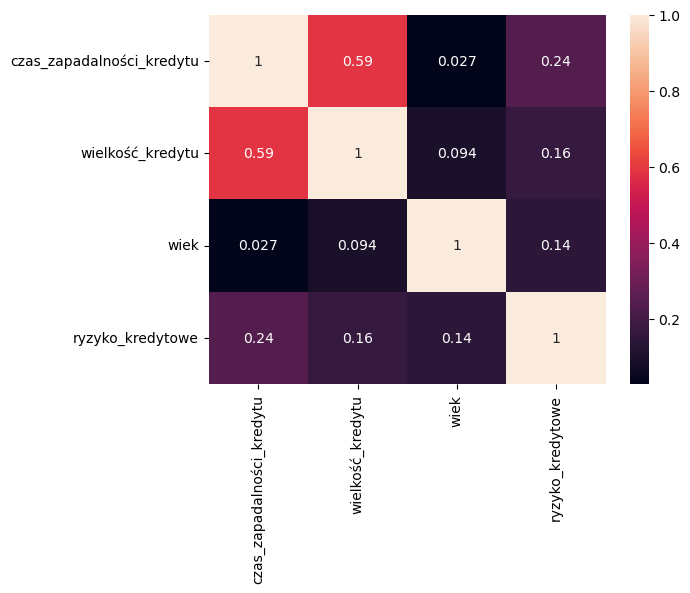

In [34]:
sns.heatmap(df.corr(numeric_only = True).abs(), annot = True)

In [35]:
#df.drop("Duration", axis = 1, inplace = True)

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1400 non-null   object
 1   czas_zapadalności_kredytu   1400 non-null   int64 
 2   historia_kredytowa          1400 non-null   object
 3   cel_kredytu                 1400 non-null   object
 4   wielkość_kredytu            1400 non-null   int64 
 5   oszczędności                1400 non-null   object
 6   czas_zatrudnienia           1400 non-null   object
 7   wysokość_raty_kredytu       1400 non-null   object
 8   status_matrymonialny        1400 non-null   object
 9   inni_kredytobiorcy          1400 non-null   object
 10  miejsce_zamieszkania        1400 non-null   object
 11  najdroższa_własność         1400 non-null   object
 12  wiek                        1400 non-null   int64 
 13  inne_kredyty                1400 non-null   object
 14  spo

In [37]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe
0,4,22,2,0,1283,5,4,4,2,1,...,2,25,3,1,1,3,2,1,2,1
1,1,12,4,2,2246,1,5,3,3,1,...,2,60,3,2,2,3,2,1,2,0
2,4,24,3,2,4151,2,3,2,3,1,...,2,35,3,2,2,3,2,1,2,1
3,3,31,2,0,7940,1,2,1,3,1,...,3,26,3,1,1,3,2,1,2,0
4,2,9,2,9,1391,1,3,2,4,1,...,1,27,1,2,1,3,2,2,2,1


In [38]:
from sklearn.preprocessing import OneHotEncoder

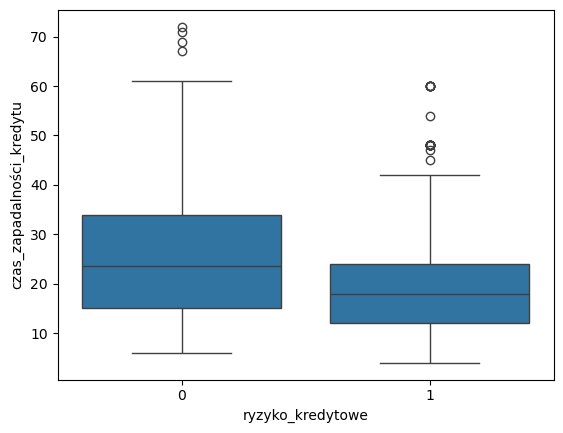

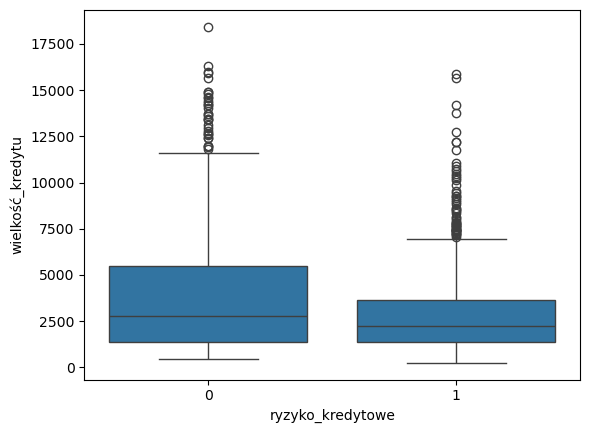

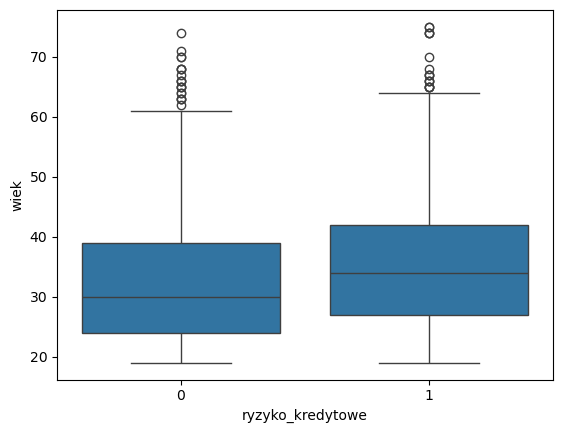

In [39]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [40]:
for i in num_cols:
    q_treshold = df[i].quantile(0.99)
    df = df[df[i] <= q_treshold]

In [41]:
num_cols

['czas_zapadalności_kredytu', 'wielkość_kredytu', 'wiek']

In [42]:
cat_cols

['stan_konta',
 'historia_kredytowa',
 'cel_kredytu',
 'oszczędności',
 'czas_zatrudnienia',
 'wysokość_raty_kredytu',
 'status_matrymonialny',
 'inni_kredytobiorcy',
 'miejsce_zamieszkania',
 'najdroższa_własność',
 'inne_kredyty',
 'sposób_opłaty_mieszkania',
 'liczba_kredytów_w_historii',
 'praca',
 'liczba_osób_na_utrzymaniu',
 'telefon',
 'cudzoziemiec']

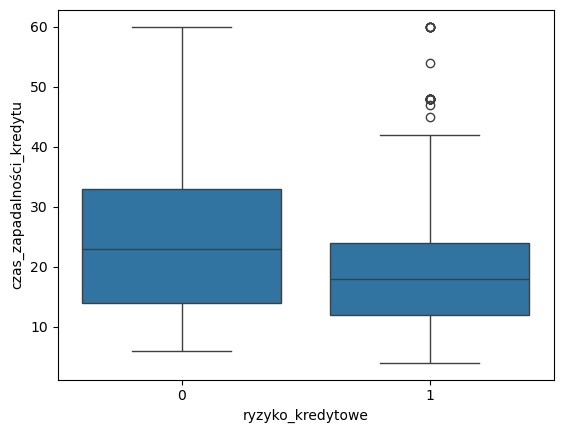

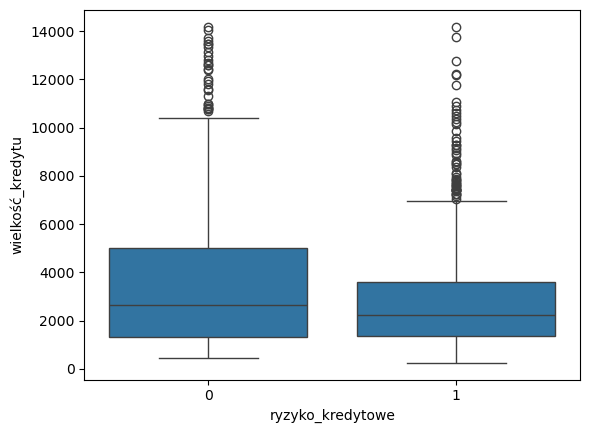

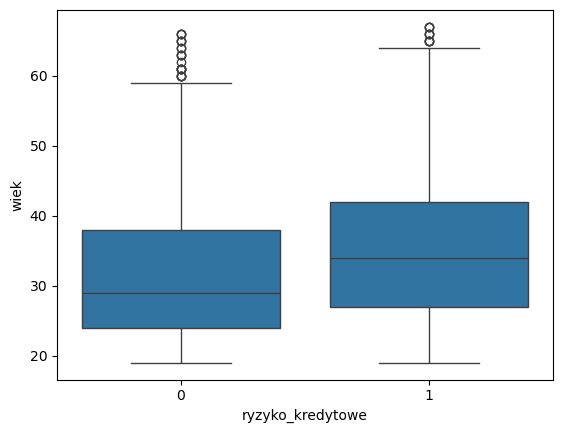

In [43]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [44]:
df.info()

<class 'pandas.DataFrame'>
Index: 1368 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1368 non-null   object
 1   czas_zapadalności_kredytu   1368 non-null   int64 
 2   historia_kredytowa          1368 non-null   object
 3   cel_kredytu                 1368 non-null   object
 4   wielkość_kredytu            1368 non-null   int64 
 5   oszczędności                1368 non-null   object
 6   czas_zatrudnienia           1368 non-null   object
 7   wysokość_raty_kredytu       1368 non-null   object
 8   status_matrymonialny        1368 non-null   object
 9   inni_kredytobiorcy          1368 non-null   object
 10  miejsce_zamieszkania        1368 non-null   object
 11  najdroższa_własność         1368 non-null   object
 12  wiek                        1368 non-null   int64 
 13  inne_kredyty                1368 non-null   object
 14  sposób_o

In [45]:
sum(df.duplicated())

0

In [46]:
df.reset_index(inplace = True, drop = True)

In [47]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe
0,4,22,2,0,1283,5,4,4,2,1,...,2,25,3,1,1,3,2,1,2,1
1,1,12,4,2,2246,1,5,3,3,1,...,2,60,3,2,2,3,2,1,2,0
2,4,24,3,2,4151,2,3,2,3,1,...,2,35,3,2,2,3,2,1,2,1
3,3,31,2,0,7940,1,2,1,3,1,...,3,26,3,1,1,3,2,1,2,0
4,2,9,2,9,1391,1,3,2,4,1,...,1,27,1,2,1,3,2,2,2,1


In [48]:
from sklearn.model_selection import train_test_split

X = df.drop("ryzyko_kredytowe", axis = 1)
y = df["ryzyko_kredytowe"]

[Text(0, 0, '677'), Text(0, 0, '691')]

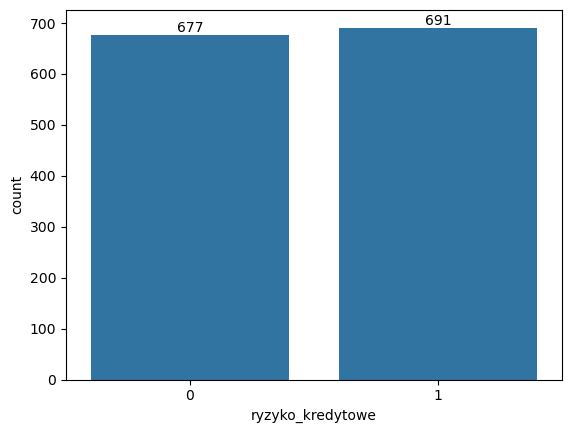

In [49]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [50]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1368 entries, 0 to 1367
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1368 non-null   object
 1   czas_zapadalności_kredytu   1368 non-null   int64 
 2   historia_kredytowa          1368 non-null   object
 3   cel_kredytu                 1368 non-null   object
 4   wielkość_kredytu            1368 non-null   int64 
 5   oszczędności                1368 non-null   object
 6   czas_zatrudnienia           1368 non-null   object
 7   wysokość_raty_kredytu       1368 non-null   object
 8   status_matrymonialny        1368 non-null   object
 9   inni_kredytobiorcy          1368 non-null   object
 10  miejsce_zamieszkania        1368 non-null   object
 11  najdroższa_własność         1368 non-null   object
 12  wiek                        1368 non-null   int64 
 13  inne_kredyty                1368 non-null   object
 14  spo

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42, stratify = y)

In [52]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(X_train[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [53]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,60,4,12,[0.18],[0.9],22.00,12.05,0.55
wielkość_kredytu,14179,276,1275,[2.29],[1.56],3310.53,2697.23,0.81
wiek,67,19,26,[0.3],[0.94],33.96,10.88,0.32


In [54]:
pos_label, neg_label = 1, 0

In [55]:
#from imblearn.over_sampling import SMOTE

In [56]:
from sklearn.preprocessing import StandardScaler

In [57]:
from sklearn.linear_model import LogisticRegression

In [58]:
from sklearn.metrics import ConfusionMatrixDisplay

In [59]:
from sklearn.compose import ColumnTransformer

def transform_data(X_train, num_cols, cat_cols, ttype):
    num_transformer = StandardScaler()

    cat_transformer = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    if ttype == 'all':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'cat':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', 'passthrough', num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'num':
         preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', 'passthrough', cat_cols)
            ],
            remainder='drop'
        )
    else:
        print("wrong param")
    
    X_train_transformed = preprocessor.fit_transform(X_train)
    feature_names = preprocessor.get_feature_names_out()
    
    X_train = pd.DataFrame(
        X_train_transformed, 
        columns = feature_names, 
        index = X_train.index
    )
    
    return preprocessor

In [60]:
def united_shapley(shap_ohe):
    feature_groups = {}
    
    for i in df.columns:
        div_columns = [j[5:] for j in X_train_transformed_df.columns if j[5:].startswith(i)]
        feature_groups[i] = div_columns
    
    if shap_ohe.values.ndim == 3:
        current_values = shap_ohe.values[:, :, 1].copy()
        current_base_values = shap_ohe.base_values[:, 1].copy()
    elif shap_ohe.values.ndim == 2:
        current_values = shap_ohe.values.copy()
        current_base_values = shap_ohe.base_values.copy()
    
    current_feature_names = [
        name[5:] if name.startswith(('num__', 'cat__')) else name 
        for name in shap_ohe.feature_names
    ]
    
    for group_name, sum_columns in feature_groups.items():
        indx = [current_feature_names.index(c) for c in sum_columns if c in current_feature_names]
    
        if indx:
            sum_shap = current_values[:, indx].sum(axis = 1)
    
            for i in sorted(indx, reverse = True):
                current_values = np.delete(current_values, i, axis = 1)
                current_feature_names.pop(i)
    
            current_values = np.c_[current_values, sum_shap]
            current_feature_names.append(group_name)
    
    new_shap_values = shap.Explanation(
            values = current_values,
            base_values = current_base_values,
            data =  X_train.values,
            feature_names = current_feature_names
        )
    
    return new_shap_values

In [61]:
#https://medium.com/@ravi.abhinav4/improving-class-imbalance-with-class-weights-in-machine-learning-af072fdd4aa4
def calculate_class_weights(y):
    unique_classes, class_counts = np.unique(y, return_counts=True)
    total_samples = len(y)
    class_weights = {}

    for class_label, class_counts in zip(unique_classes, class_counts):
        class_weight = total_samples / (2.0 * class_counts)
        class_weights[class_label] = class_weight

    class_weight0 = class_weights[0]
    class_weight1 = class_weights[1]

    print(f'Weight for class 0: ', class_weight0)
    print(f'Weight for class 1: ', class_weight1)

In [62]:
calculate_class_weights(y)

Weight for class 0:  1.0103397341211227
Weight for class 1:  0.9898697539797395


In [63]:
class_weights = {0: 1.7017543859649122, 1: 0.708029197080292}

In [64]:
from sklearn.model_selection import LearningCurveDisplay, RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 10, random_state = 42)

In [65]:
from sklearn.model_selection import TunedThresholdClassifierCV

In [66]:
from imblearn.pipeline import Pipeline

In [67]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

from sklearn.model_selection import ShuffleSplit

def lower_bound(cv_results):
    best_score_idx = np.argmax(cv_results["mean_test_neg_brier_score"])
    return (
        cv_results["mean_test_neg_brier_score"][best_score_idx]
        - cv_results["std_test_neg_brier_score"][best_score_idx])

def best_low_complexity(cv_results):
    threshold = lower_bound(cv_results)
    candidate_idx = np.flatnonzero(cv_results["mean_test_neg_brier_score"] >= threshold)
    best_idx = candidate_idx[
        cv_results["param_reduce_dim__n_components"][candidate_idx].argmin()
    ]
    return best_idx

In [68]:
from sklearn.metrics import confusion_matrix

def fpr_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])
    tn, fp, _, _ = cm.ravel()
    tnr = tn / (tn + fp)
    return 1 - tnr

In [69]:
from sklearn.metrics import make_scorer, precision_score, recall_score, accuracy_score

tpr_score = recall_score  # TPR and recall are the same metric
scr = {
    "precision": make_scorer(precision_score, pos_label=pos_label, zero_division = 0),
    "recall": make_scorer(recall_score, pos_label=pos_label),
    "bad_recall" : make_scorer(recall_score, pos_label=pos_label, zero_division = 0),
    "fpr": make_scorer(fpr_score, neg_label=neg_label, pos_label=pos_label,  greater_is_better = False),
    "tpr": make_scorer(tpr_score, pos_label=pos_label),
    'accuracy': make_scorer(accuracy_score, neg_label=neg_label, pos_label=pos_label)
}

In [70]:
import numpy as np

def credit_gain_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])

    gain_matrix = np.array(
        [
            [0, -1],
            [-5, 0],
        ]
    )
    return np.sum(cm * gain_matrix)


scr["credit_gain"] = make_scorer(
    credit_gain_score, neg_label=neg_label, pos_label=pos_label
)

In [71]:
lr = LogisticRegression(random_state = 42, class_weight = "balanced")

In [72]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 957 entries, 39 to 515
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  957 non-null    object
 1   czas_zapadalności_kredytu   957 non-null    int64 
 2   historia_kredytowa          957 non-null    object
 3   cel_kredytu                 957 non-null    object
 4   wielkość_kredytu            957 non-null    int64 
 5   oszczędności                957 non-null    object
 6   czas_zatrudnienia           957 non-null    object
 7   wysokość_raty_kredytu       957 non-null    object
 8   status_matrymonialny        957 non-null    object
 9   inni_kredytobiorcy          957 non-null    object
 10  miejsce_zamieszkania        957 non-null    object
 11  najdroższa_własność         957 non-null    object
 12  wiek                        957 non-null    int64 
 13  inne_kredyty                957 non-null    object
 14  sposób_op

In [73]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import FixedThresholdClassifier

clf_lr = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LogisticRegression(random_state = 42, class_weight = "balanced"))])

In [104]:
from scipy.stats import randint, loguniform

param_distributions = [{'classifier__C': loguniform(0.1, 10),
               'classifier__solver': ['liblinear'],
               'classifier__l1_ratio': [0, 1],
               'classifier__max_iter' : randint(1000, 1500)}]

In [105]:
from sklearn.metrics import fbeta_score

In [106]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

model = RandomizedSearchCV(clf_lr, 
                           param_distributions = param_distributions, 
                           cv = cv, 
                           n_jobs = 1, 
                           refit = 'recall', 
                           n_iter = 10, 
                           scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                           return_train_score = True, 
                           random_state = 42)

In [107]:
model.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'classifier__C': <scipy.stats....0027DE20572F0>, 'classifier__l1_ratio': [0, 1], 'classifier__max_iter': <scipy.stats....0027DE2055010>, 'classifier__solver': ['liblinear']}]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide

In [108]:
best_model = model.best_estimator_

In [109]:
results = pd.DataFrame(model.cv_results_)

In [110]:
from sklearn.metrics import PrecisionRecallDisplay, auc, precision_recall_curve, f1_score

In [111]:
def cv_cm(cv_object, y_train):
    total_train_obs = y_train.shape[0]
    cv_results = pd.DataFrame(cv_object.cv_results_)
    best_estimator_results = cv_results.iloc[cv_results['mean_test_recall'].idxmax(), :]

    recall = best_estimator_results.mean_test_recall
    precision = best_estimator_results.mean_test_precision
    accuracy = best_estimator_results.mean_test_accuracy

    true_positives = ((precision * recall) * (total_train_obs - (accuracy * total_train_obs))) / (recall - (2 * recall * precision) + precision)
    false_positives = round((true_positives - (precision * true_positives)) / precision, 0)
    false_negatives = round((true_positives - (recall * true_positives)) / recall, 0)

    print(f'accuracy: ', accuracy)
    print(f'recall: ', recall)
    print(f'precision: ', precision)
    
    true_negatives = round((accuracy * total_train_obs) - true_positives, 0)
    true_positives = round(true_positives, 0)

    prediction_list = [true_negatives, false_positives, false_negatives, true_positives]
    prediction_matrix = np.array(prediction_list).reshape(2, 2)

    plt.figure(figsize = (5, 4))
    ax = sns.heatmap(prediction_matrix, vmin = 0, vmax = total_train_obs, annot = True,
                    cmap = sns.color_palette('Spectral', as_cmap = True), fmt = 'g')
    plt.title('Confusion Matrix', fontsize = 16)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    return plt.show()
    return cv_results

accuracy:  0.7539305191972078
recall:  0.7482839347079038
precision:  0.7610947017471194


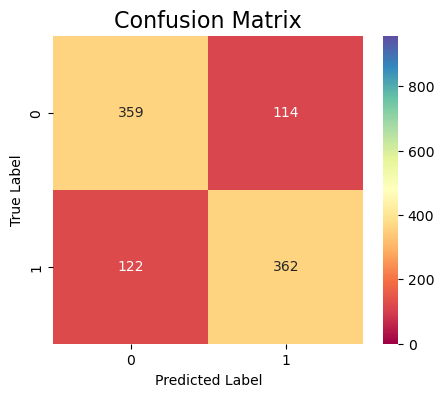

In [112]:
cv_cm(model, y_train)

In [113]:
#https://stackoverflow.com/questions/73582838/what-is-predict-proba-and-1-after-x-test-in-code
#column index 0 => negative class predictions
#column index 1 => positive class predictions

def set_threshold(chosen_model):
    y_scores = chosen_model.predict_proba(X_test)[:, 1]
    
    precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
    auc_score = auc(recall, precision)
    
    with np.errstate(divide='ignore', invalid='ignore'):
        f1s = 2 * (precision * recall) / (precision + recall)
        f1s[np.isnan(f1s)] = 0  
    
    best_thresh = thresholds[f1s.argmax()]
    print("Best threshold:", best_thresh)
    
    y_pred_reg_opt = (y_scores >= best_thresh).astype(int)
    return y_pred_reg_opt

In [114]:
from sklearn.metrics import RocCurveDisplay, auc
from sklearn.model_selection import cross_validate

def roc_cv(best_model):
    n_splits = 5
    cv = 5
    cv_results = cross_validate(
        best_model, X, y, cv=cv, return_estimator=True, return_indices=True
    )
    
    prop_cycle = plt.rcParams["axes.prop_cycle"]
    colors = prop_cycle.by_key()["color"]
    curve_kwargs_list = [
        dict(alpha=0.3, lw=1, color=colors[fold % len(colors)]) for fold in range(n_splits)
    ]
    names = [f"ROC fold {idx}" for idx in range(n_splits)]
    
    mean_fpr = np.linspace(0, 1, 100)
    interp_tprs = []
    
    _, ax = plt.subplots(figsize=(6, 6))
    viz = RocCurveDisplay.from_cv_results(
        cv_results,
        X,
        y,
        ax=ax,
        name=names,
        curve_kwargs=curve_kwargs_list,
        plot_chance_level=True,
    )
    
    for idx in range(n_splits):
        interp_tpr = np.interp(mean_fpr, viz.fpr[idx], viz.tpr[idx])
        interp_tpr[0] = 0.0
        interp_tprs.append(interp_tpr)
    
    mean_tpr = np.mean(interp_tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(viz.roc_auc)
    
    ax.plot(
        mean_fpr,
        mean_tpr,
        color="b",
        label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
        lw=2,
        alpha=0.8,
    )
    
    std_tpr = np.std(interp_tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    ax.fill_between(
        mean_fpr,
        tprs_lower,
        tprs_upper,
        color="grey",
        alpha=0.2,
        label=r"$\pm$ 1 std. dev.",
    )
    
    ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate"
    )
    ax.legend(loc="lower right")
    plt.show()

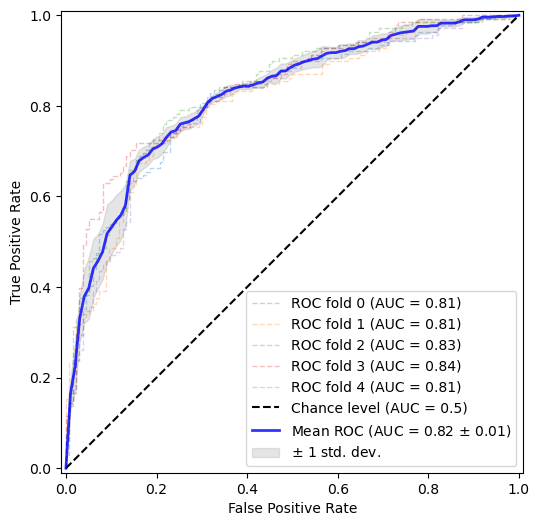

In [115]:
roc_cv(best_model)

In [116]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

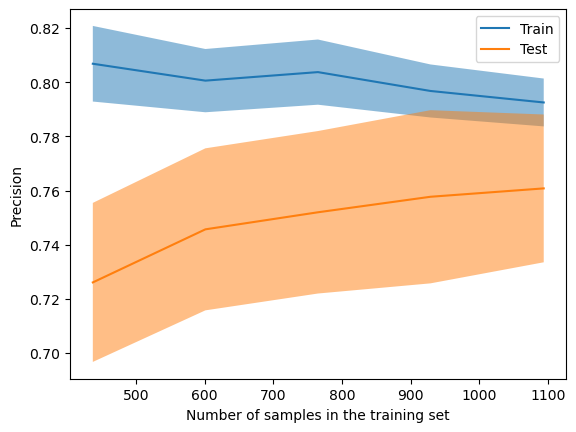

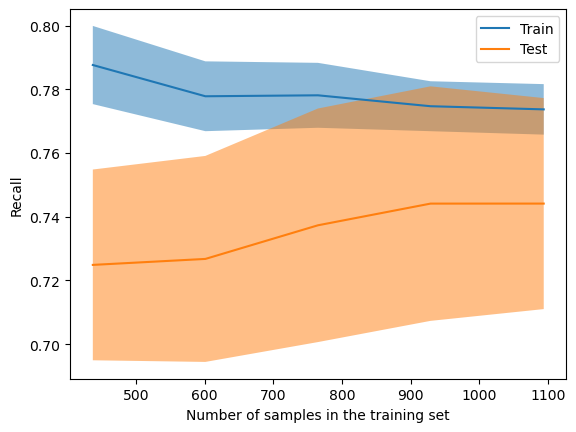

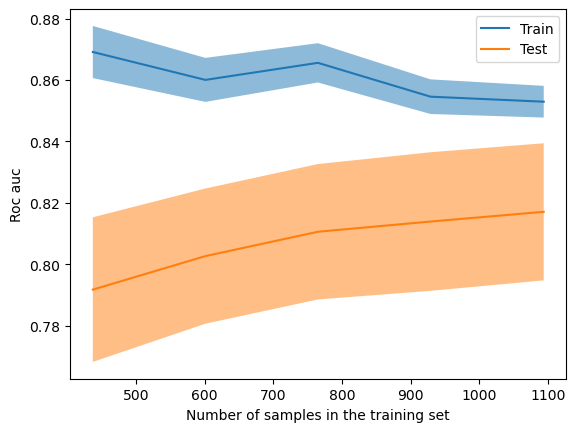

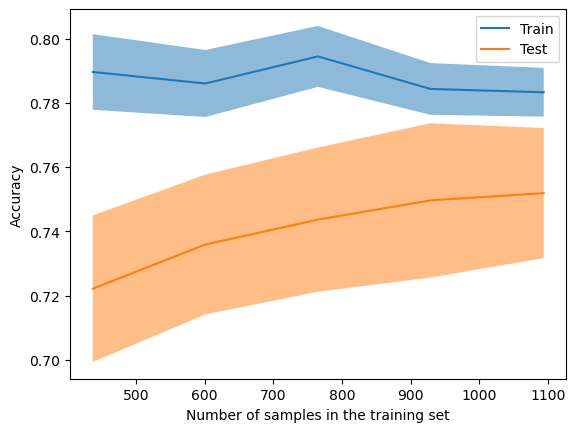

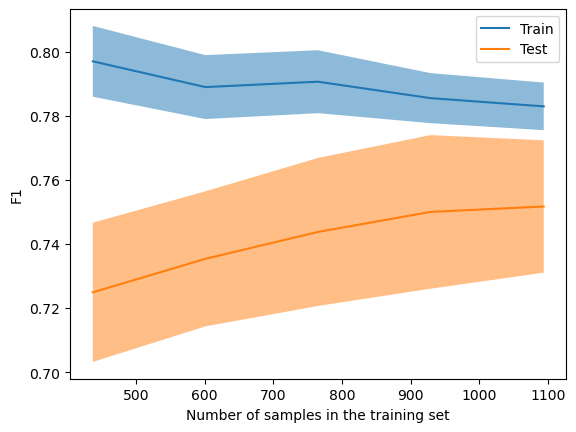

In [117]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_model, X, y, scoring = i, cv = cv, train_sizes = train_sizes, error_score = "raise")

In [118]:
from sklearn.model_selection import cross_val_score

def model_evaluation(estimator):

    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats = 5, random_state=42)
    metrics = {"accuracy", "roc_auc", "f1", "precision", "recall"}
    
    for i in metrics:
        scores = cross_val_score(estimator, X, y, scoring=i, cv=cv)
        
        print("Mean " + i + ":", scores.mean())
        print("Standard deviation:", scores.std())
        print("\n")

In [119]:
model_evaluation(best_model)

Mean precision: 0.7628480858123597
Standard deviation: 0.03030653524137171


Mean recall: 0.7475904493796267
Standard deviation: 0.027910123257476695


Mean roc_auc: 0.8194116853150046
Standard deviation: 0.023423330496198793


Mean accuracy: 0.7542461431512527
Standard deviation: 0.020907015889129812


Mean f1: 0.754513559423854
Standard deviation: 0.01932792452774337




In [120]:
import shap

In [121]:
best_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

In [122]:
best_model = best_model.named_steps['classifier']

In [123]:
fitted_preprocessor = clf_lr.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [124]:
explainer = shap.Explainer(best_model, X_train_transformed_df, model_output = 'probability')
shap_values_ohe = explainer(X_train_transformed_df)
shap_values = united_shapley(shap_values_ohe)

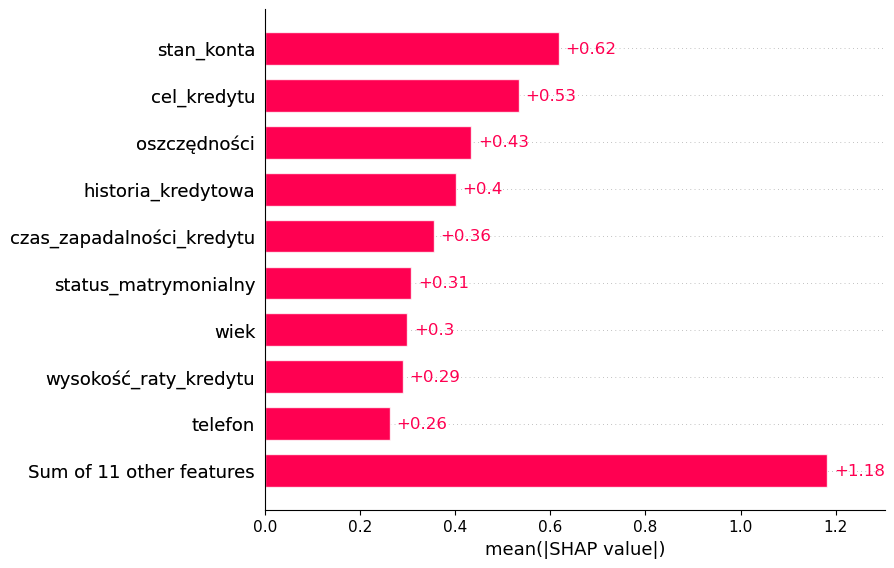

In [125]:
shap.plots.bar(shap_values)

In [126]:
X_train.iloc[1]

stan_konta                       1
czas_zapadalności_kredytu       38
historia_kredytowa               0
cel_kredytu                      5
wielkość_kredytu              5699
oszczędności                     1
czas_zatrudnienia                3
wysokość_raty_kredytu            3
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            38
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       3
praca                            2
liczba_osób_na_utrzymaniu        1
telefon                          1
cudzoziemiec                     2
Name: 414, dtype: object

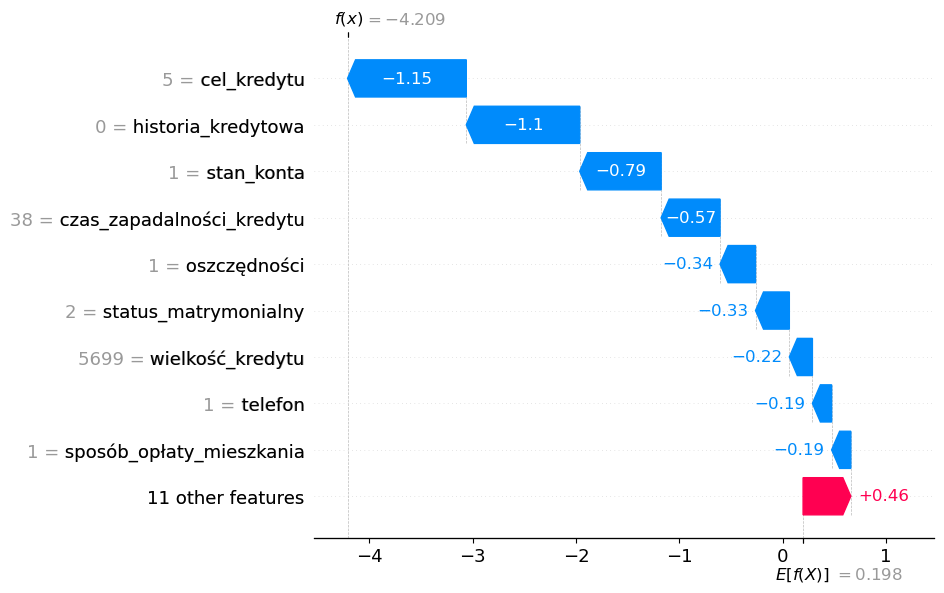

In [127]:
shap.plots.waterfall(shap_values[1], show=True)

In [128]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      0
wielkość_kredytu              1207
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              2
wiek                            24
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 896, dtype: object

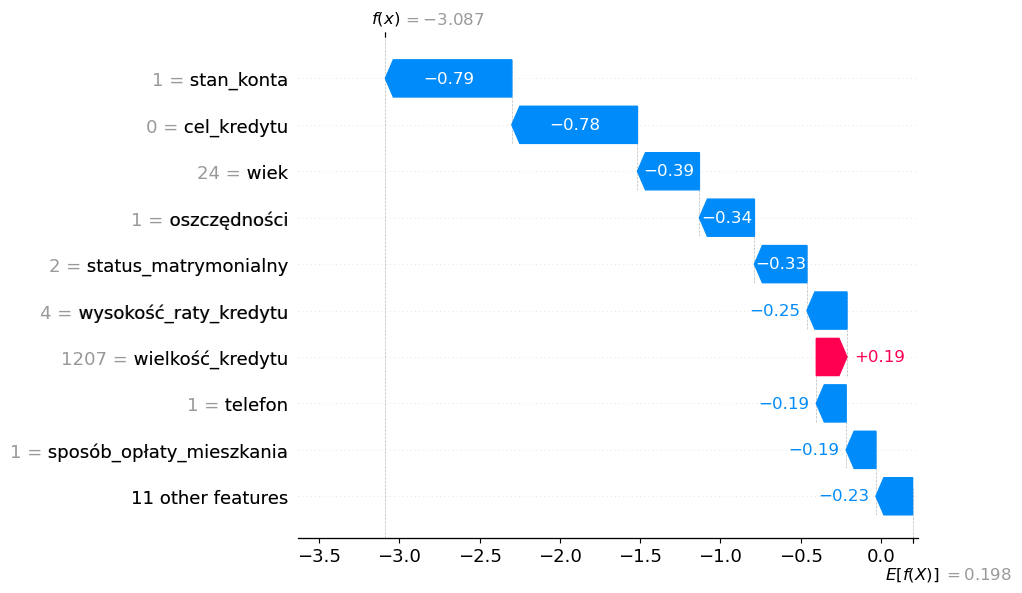

In [129]:
shap.plots.waterfall(shap_values[150], show=True)

In [130]:
X_train.iloc[250]

stan_konta                       1
czas_zapadalności_kredytu       37
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              5633
oszczędności                     1
czas_zatrudnienia                1
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             2
najdroższa_własność              3
wiek                            36
inne_kredyty                     3
sposób_opłaty_mieszkania         3
liczba_kredytów_w_historii       2
praca                            4
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 318, dtype: object

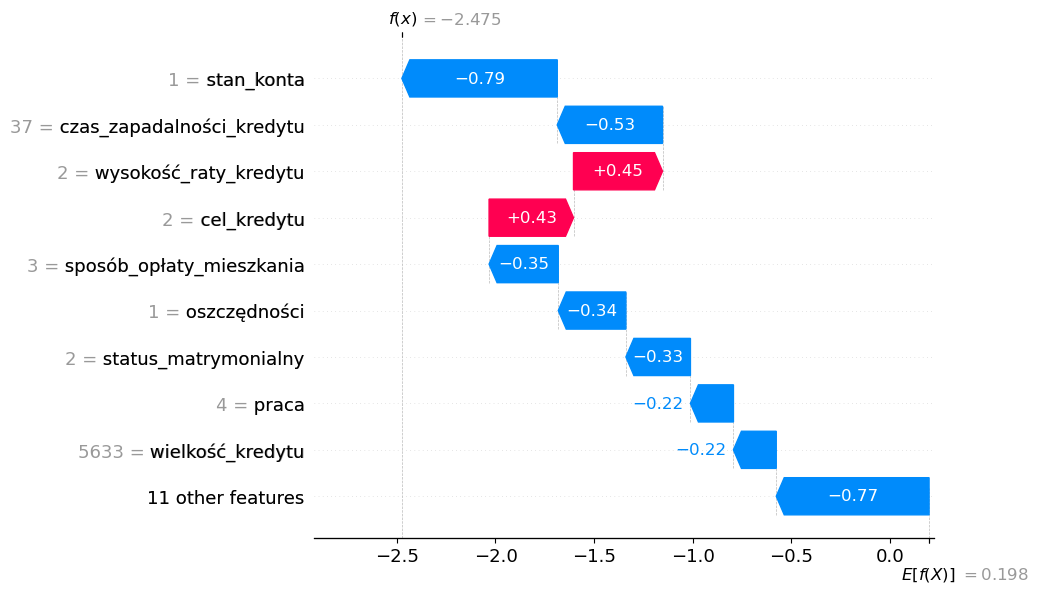

In [131]:
shap.plots.waterfall(shap_values[250], show=True)

In [132]:
from sklearn.metrics import brier_score_loss

In [133]:
y_scores = best_model.predict_proba(X_test_transformed)[:, 1]

In [134]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.1772886612541826

In [135]:
y_predicted = best_model.predict(X_test_transformed)

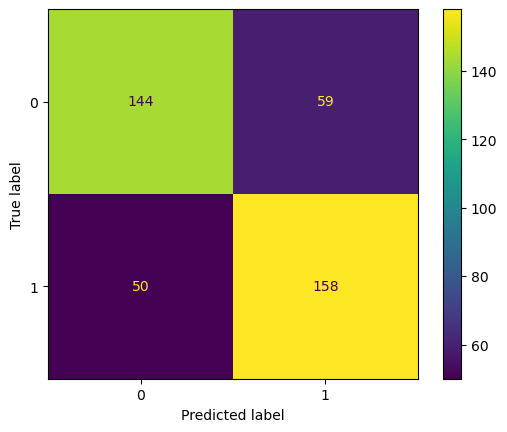

In [136]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

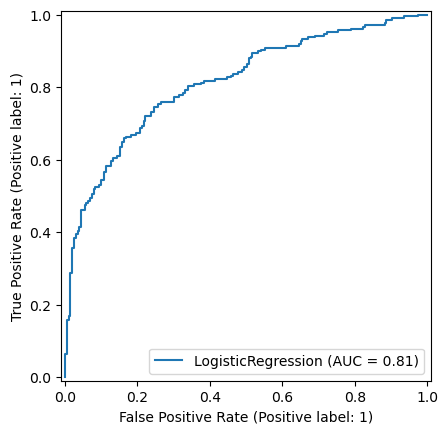

In [137]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(best_model, X_test_transformed, y_test)

In [138]:
accuracy_score(y_test, y_predicted)

0.7347931873479319

In [139]:
recall_score(y_test, y_predicted)

0.7596153846153846

In [140]:
precision_score(y_test, y_predicted)

0.728110599078341

In [141]:
from sklearn.metrics import brier_score_loss

In [142]:
from sklearn.svm import LinearSVC

In [143]:
from imblearn.pipeline import Pipeline

In [144]:
np.random.seed(42)
clf_svc = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LinearSVC(random_state = 42))])

In [147]:
from scipy.stats import randint, loguniform

param_distributions = {
    'classifier__C': loguniform(0.1, 10),
    'classifier__penalty': ['l1', 'l2'],
    'classifier__max_iter' : randint(8000, 9000)
}

In [148]:
model_svc = RandomizedSearchCV(clf_svc, 
                              param_distributions = param_distributions, 
                              scoring = ['precision', 'recall', 'accuracy', 'f1', 'balanced_accuracy'],
                              n_iter = 10,
                              n_jobs = 1, 
                              cv = cv, 
                              random_state = 42, 
                              refit = 'balanced_accuracy')

In [149]:
model_svc.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__C': <scipy.stats....0027DEE06E8B0>, 'classifier__max_iter': <scipy.stats....0027DEE06E7A0>, 'classifier__penalty': ['l1', 'l2']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['precision', 'recall', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscros

In [150]:
pd.DataFrame(model_svc.cv_results_)[['rank_test_precision', 'mean_test_precision', 'std_test_precision']].sort_values(by = "rank_test_precision")

,rank_test_precision,mean_test_precision,std_test_precision
3,1,0.764765,0.035040
2,2,0.761905,0.033914
7,3,0.761648,0.034016
5,4,0.758524,0.036608
8,5,0.757427,0.036663
0,6,0.757062,0.035626
9,7,0.755663,0.035305
4,8,0.754981,0.035123
1,9,0.754685,0.036029
6,10,0.754294,0.035033


In [151]:
best_svc = model_svc.best_estimator_

In [152]:
y_pred_best = best_svc.predict(X_test)

In [153]:
y_scores = best_svc.predict(X_test)

accuracy:  0.7502743237347296
recall:  0.7482925257731958
precision:  0.7556626695965837


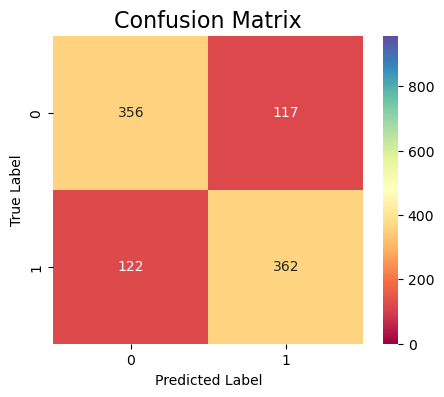

In [154]:
cv_cm(model_svc, y_train)

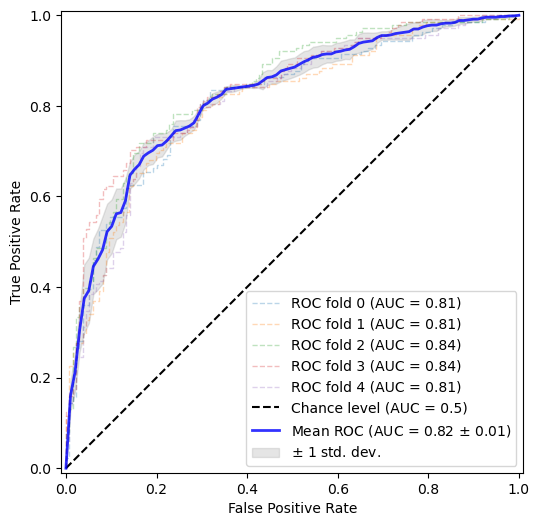

In [155]:
roc_cv(model_svc)

In [156]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

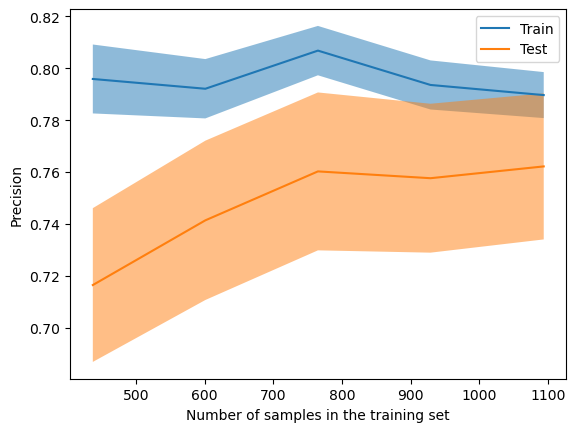

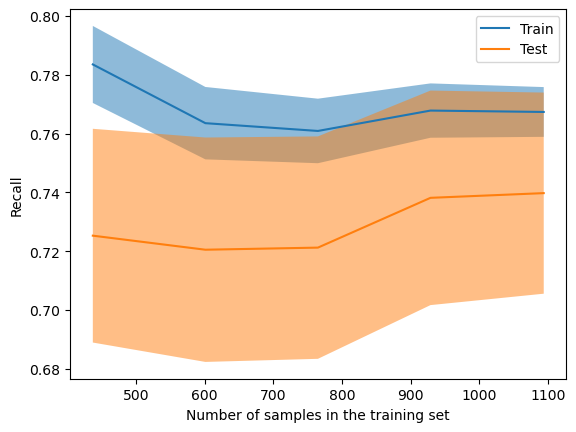

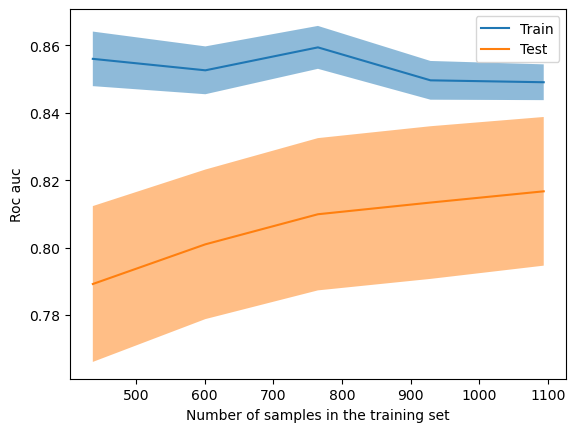

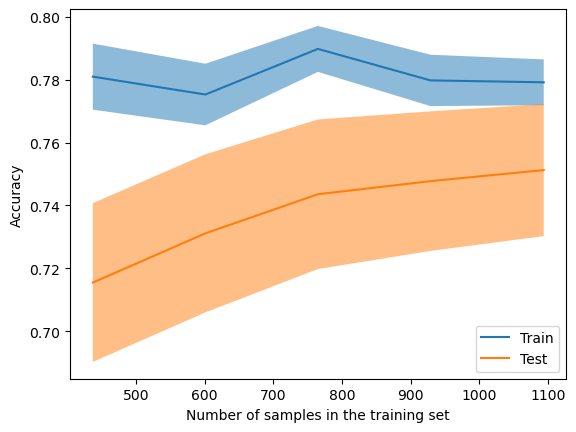

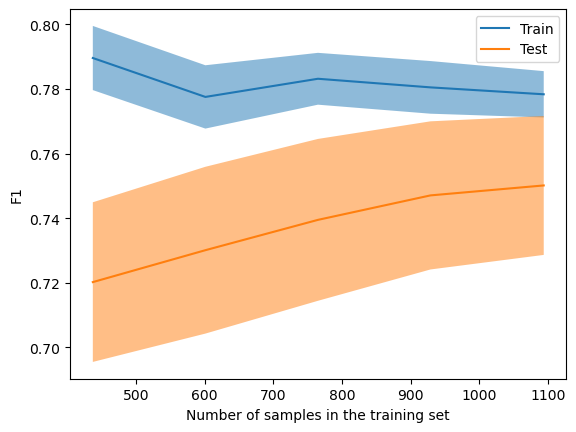

In [157]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_svc, X, y, scoring = i, cv = cv, train_sizes = train_sizes)

In [158]:
model_evaluation(best_svc)

Mean precision: 0.7654960755805854
Standard deviation: 0.03095320608406055


Mean recall: 0.7420894588676884
Standard deviation: 0.03298098276667199


Mean roc_auc: 0.8188641920791301
Standard deviation: 0.022712079895745967


Mean accuracy: 0.7539568460736344
Standard deviation: 0.021526087553576986


Mean f1: 0.7528230852518477
Standard deviation: 0.020962215927617024




In [159]:
best_svc.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. Th

In [160]:
best_svc = best_svc.named_steps['classifier']

In [161]:
fitted_preprocessor = clf_svc.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.fit_transform(X_train)
X_test_transformed = fitted_preprocessor.fit_transform(X_test)

In [162]:
feature_names = fitted_preprocessor.get_feature_names_out()

In [163]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [164]:
svc_explainer = shap.Explainer(best_svc, X_train_transformed_df)
svc_shap_values = svc_explainer(X_train_transformed_df)
svc_shap_values = united_shapley(svc_shap_values)

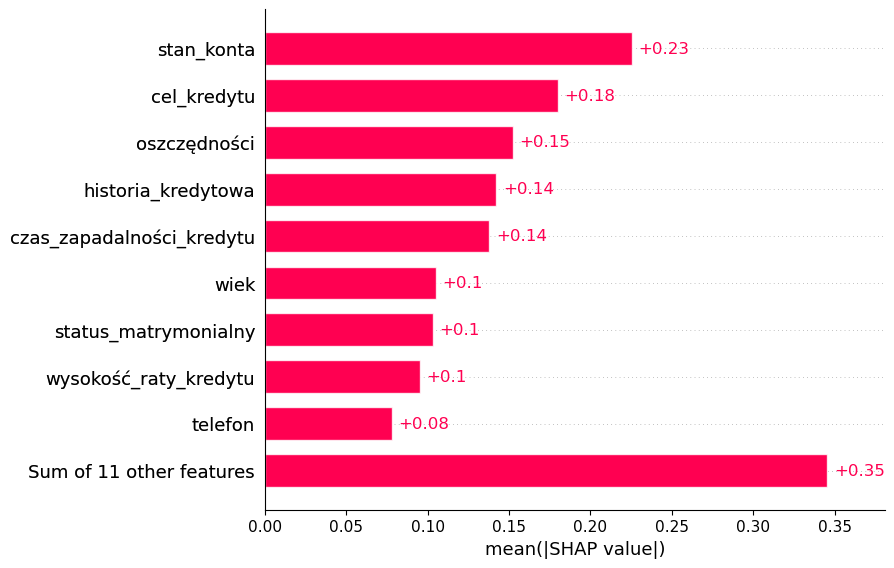

In [165]:
shap.plots.bar(svc_shap_values)

In [166]:
X_train.iloc[1]

stan_konta                       1
czas_zapadalności_kredytu       38
historia_kredytowa               0
cel_kredytu                      5
wielkość_kredytu              5699
oszczędności                     1
czas_zatrudnienia                3
wysokość_raty_kredytu            3
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            38
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       3
praca                            2
liczba_osób_na_utrzymaniu        1
telefon                          1
cudzoziemiec                     2
Name: 414, dtype: object

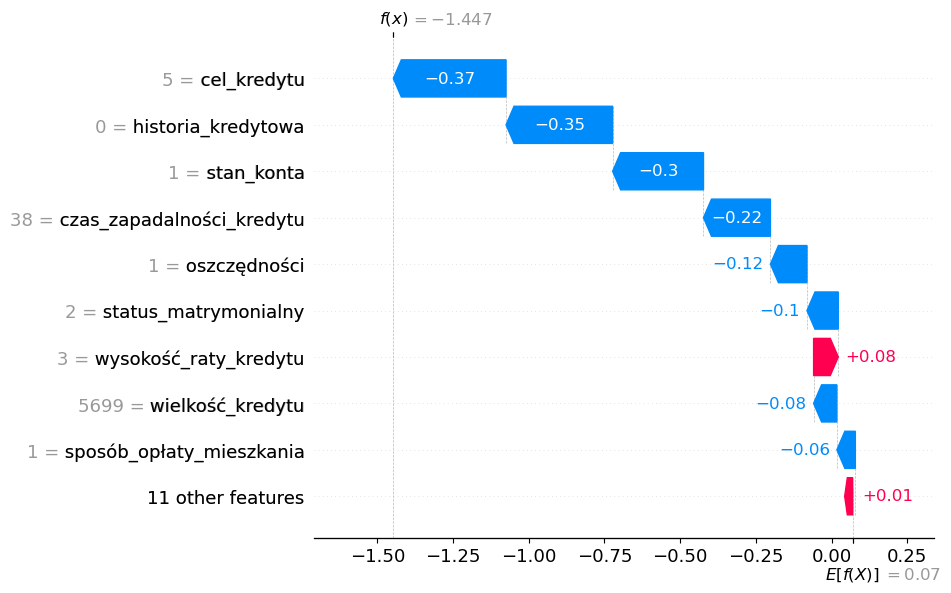

In [167]:
shap.plots.waterfall(svc_shap_values[1], show=True)

In [168]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      0
wielkość_kredytu              1207
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              2
wiek                            24
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 896, dtype: object

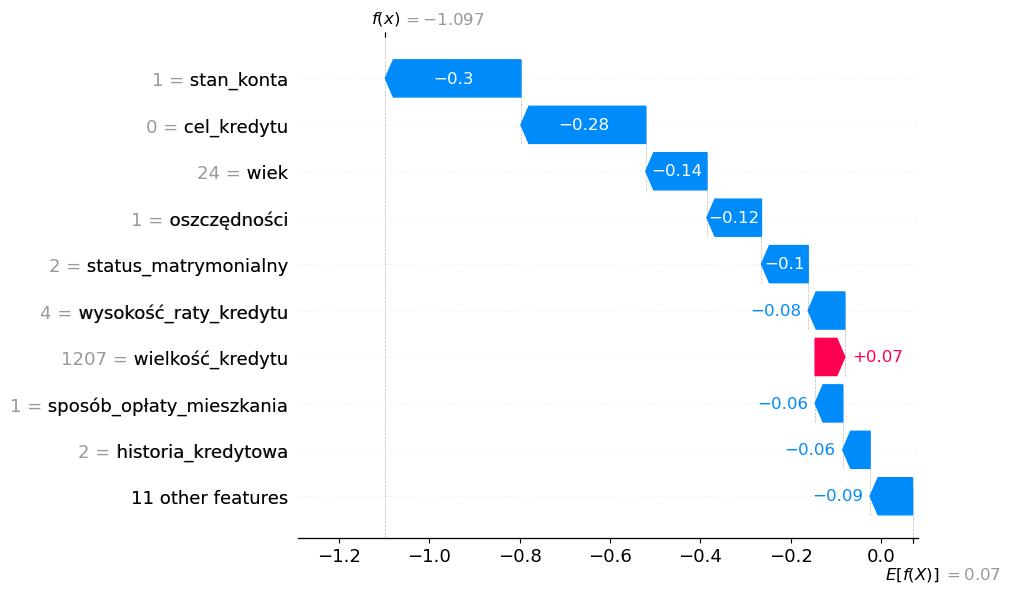

In [169]:
shap.plots.waterfall(svc_shap_values[150], show=True)

In [170]:
X_train.iloc[250]

stan_konta                       1
czas_zapadalności_kredytu       37
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              5633
oszczędności                     1
czas_zatrudnienia                1
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             2
najdroższa_własność              3
wiek                            36
inne_kredyty                     3
sposób_opłaty_mieszkania         3
liczba_kredytów_w_historii       2
praca                            4
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 318, dtype: object

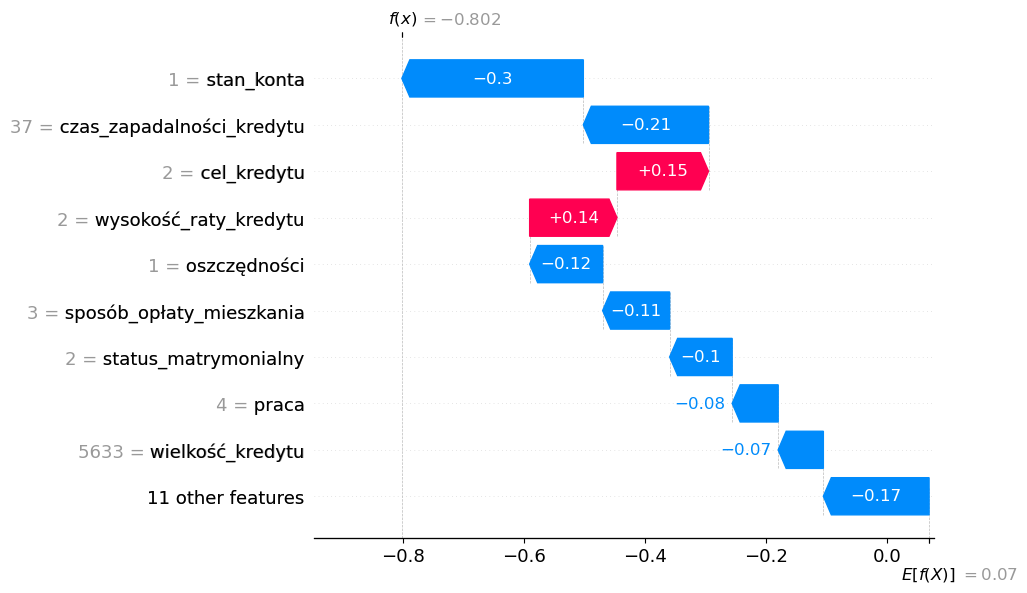

In [171]:
shap.plots.waterfall(svc_shap_values[250], show=True)

In [172]:
from sklearn.metrics import brier_score_loss

In [173]:
y_scores = best_svc.predict(X_test_transformed)

In [174]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.25790754257907544

In [175]:
y_predicted = best_svc.predict(X_test_transformed)

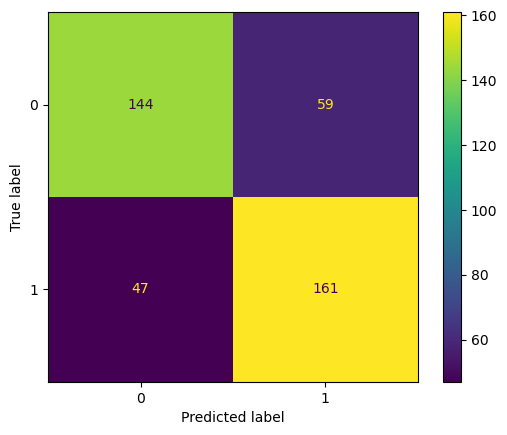

In [176]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

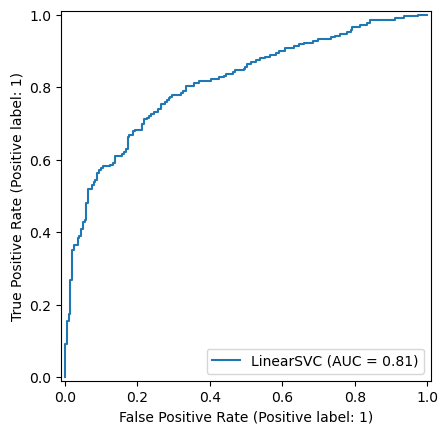

In [177]:
RocCurveDisplay.from_estimator(best_svc, X_test_transformed, y_test)

In [178]:
accuracy_score(y_test, y_predicted)

0.7420924574209246

In [181]:
recall_score(y_test, y_predicted)

0.7740384615384616

In [182]:
precision_score(y_test, y_predicted)

0.7318181818181818

In [187]:
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

In [188]:
rf = RandomForestClassifier(random_state = 42)

In [189]:
clf_rf = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'cat')),
    ('classifier', RandomForestClassifier(random_state = 42))])

In [297]:
param_distributions = {
    'classifier__n_estimators': randint(80, 100),
    'classifier__max_depth': randint(2, 3),
    'classifier__min_samples_split': randint(10, 15),
    'classifier__min_samples_leaf': randint(2, 7),
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__criterion': ['gini', 'entropy']
}

In [298]:
model_rf = RandomizedSearchCV(clf_rf, 
                              param_distributions = param_distributions, 
                              cv = cv, 
                              n_iter = 5, 
                              n_jobs = -1, 
                              scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                              return_train_score = True, 
                              refit = 'balanced_accuracy', 
                              random_state = 42,
                             error_score = 'raise')

In [299]:
model_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': <scipy.stats....0027DE1DC9470>, 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': <scipy.stats....0027DE87209F0>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits

In [300]:
best_rf = model_rf.best_estimator_

accuracy:  0.7306489965095986
recall:  0.7224377147766323
precision:  0.7389656037150968


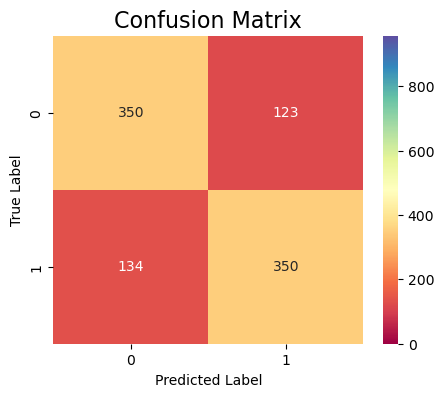

In [301]:
cv_cm(model_rf, y_train)

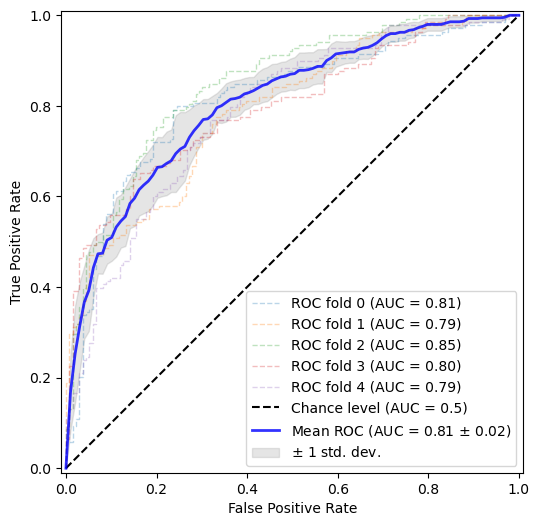

In [302]:
roc_cv(model_rf)

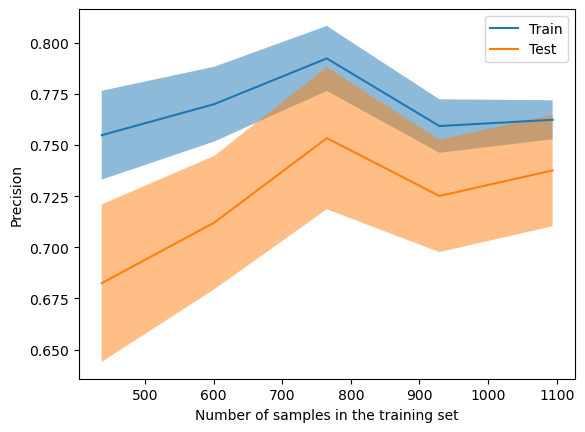

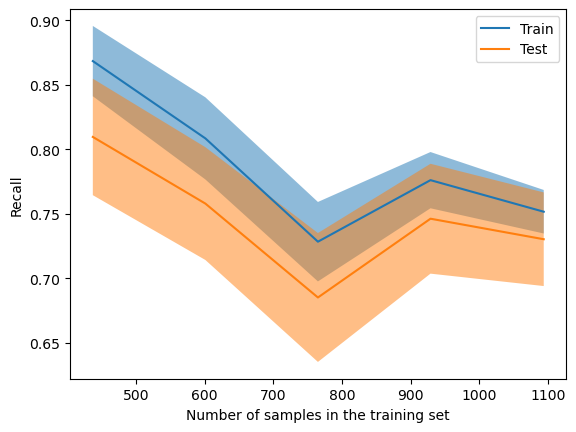

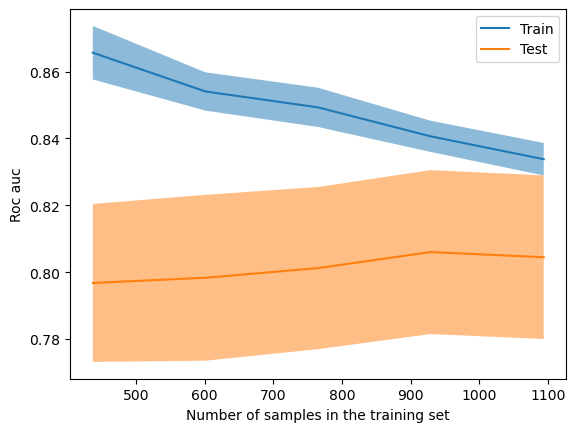

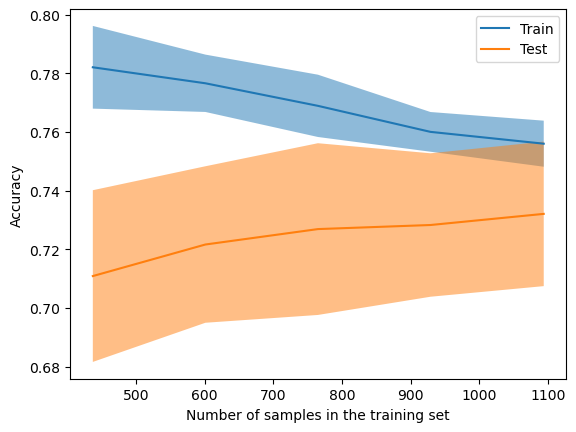

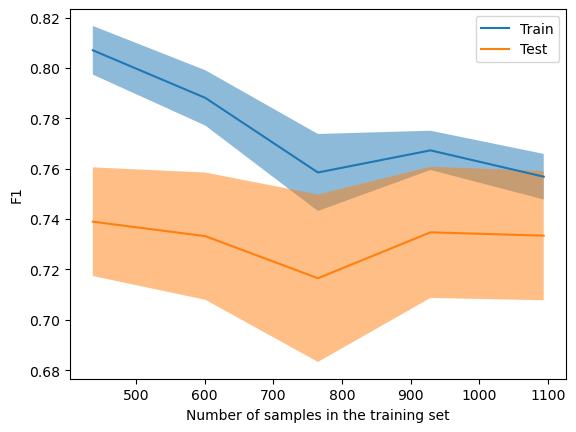

In [303]:
for i in evals:
     display = LearningCurveDisplay.from_estimator(best_rf, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

In [304]:
model_evaluation(best_rf)

Mean precision: 0.7418285238502206
Standard deviation: 0.03068029526999088


Mean recall: 0.7308163903659681
Standard deviation: 0.04233420823628815


Mean roc_auc: 0.8060953725226696
Standard deviation: 0.02839272460185302


Mean accuracy: 0.7350990615224192
Standard deviation: 0.028403135853760655


Mean f1: 0.7356257678355647
Standard deviation: 0.030312973313203494




In [305]:
best_rf.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

In [306]:
best_rf = best_rf.named_steps['classifier']

In [307]:
fitted_preprocessor = clf_rf.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [308]:
rf_explainer = shap.TreeExplainer(best_rf, X_train_transformed_df, model_output = 'probability')
rf_shap_values = rf_explainer(X_train_transformed_df)
rf_shap_values = united_shapley(rf_shap_values)

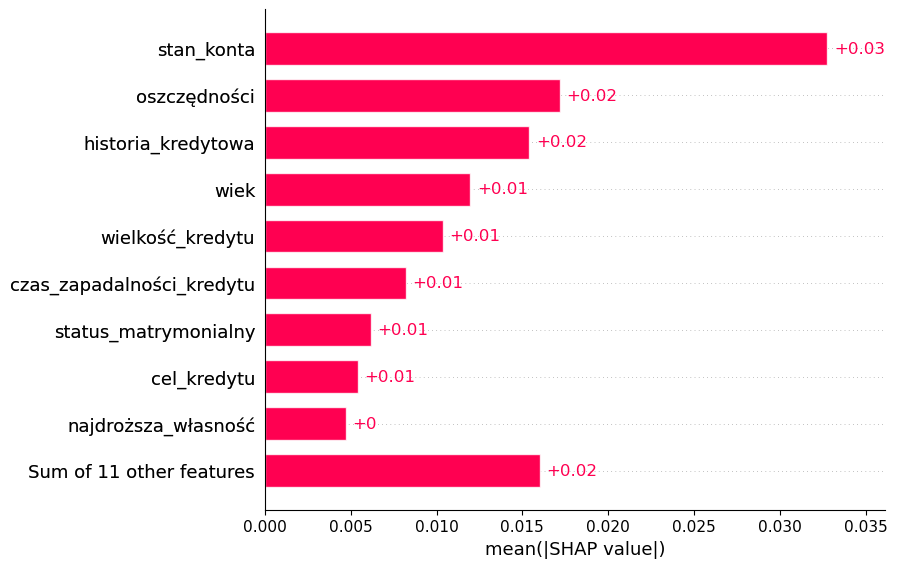

In [309]:
shap.plots.bar(rf_shap_values)

In [310]:
X_train.iloc[1]

stan_konta                       1
czas_zapadalności_kredytu       38
historia_kredytowa               0
cel_kredytu                      5
wielkość_kredytu              5699
oszczędności                     1
czas_zatrudnienia                3
wysokość_raty_kredytu            3
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            38
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       3
praca                            2
liczba_osób_na_utrzymaniu        1
telefon                          1
cudzoziemiec                     2
Name: 414, dtype: object

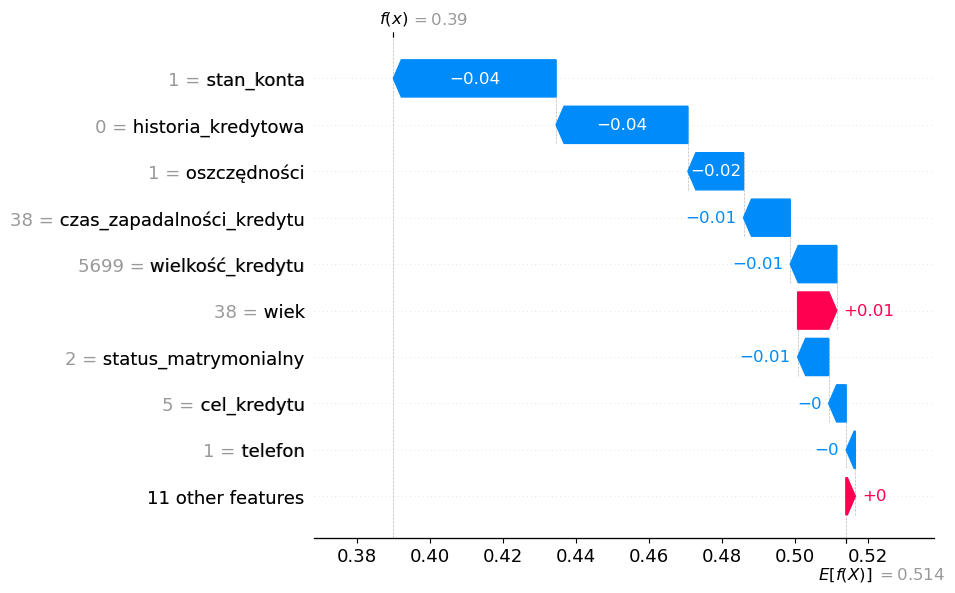

In [311]:
shap.plots.waterfall(rf_shap_values[1], max_display = 10, show=True)

In [312]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      0
wielkość_kredytu              1207
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              2
wiek                            24
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 896, dtype: object

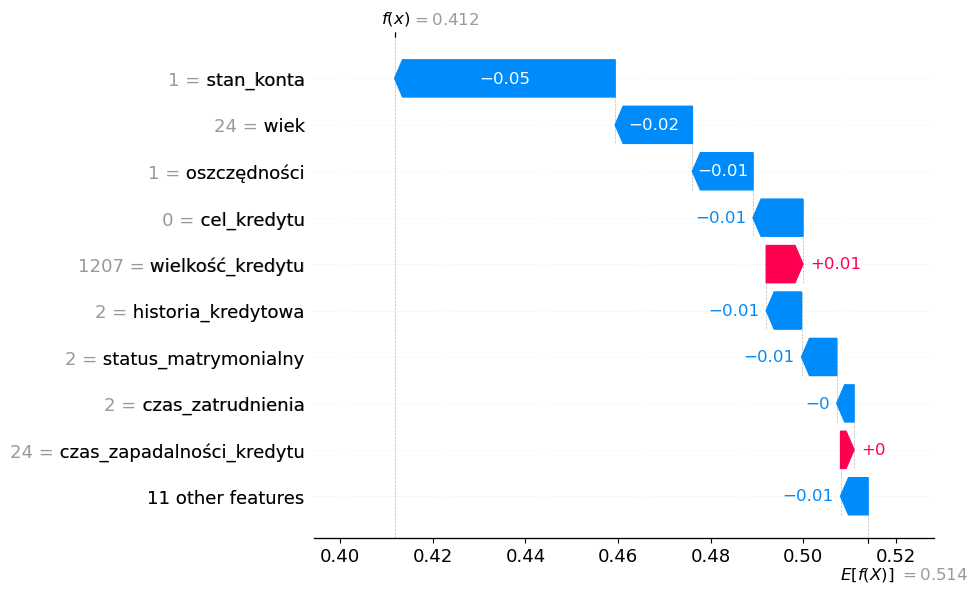

In [313]:
shap.plots.waterfall(rf_shap_values[150], max_display = 10, show=True)

In [314]:
X_train.iloc[250]

stan_konta                       1
czas_zapadalności_kredytu       37
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              5633
oszczędności                     1
czas_zatrudnienia                1
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             2
najdroższa_własność              3
wiek                            36
inne_kredyty                     3
sposób_opłaty_mieszkania         3
liczba_kredytów_w_historii       2
praca                            4
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 318, dtype: object

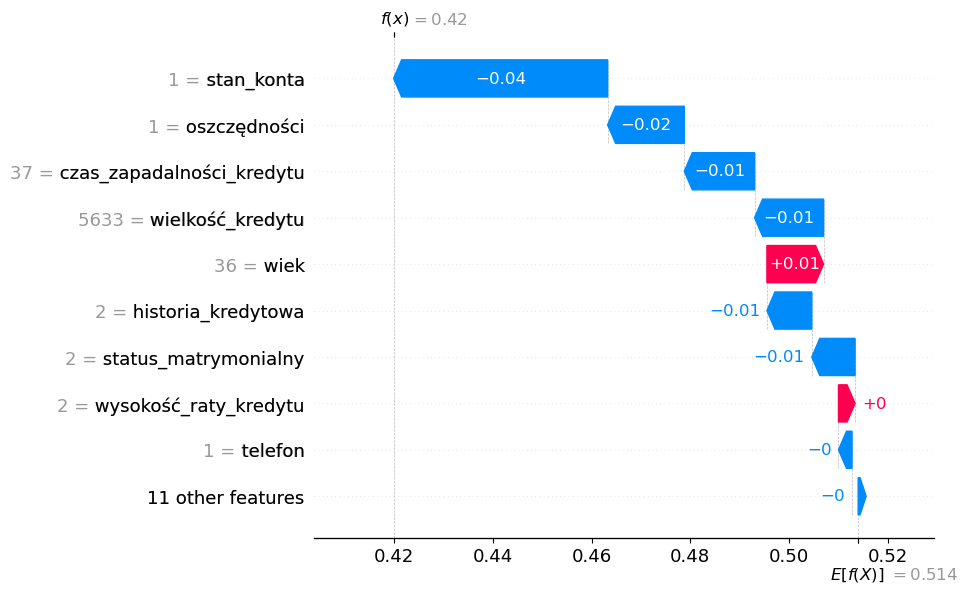

In [315]:
shap.plots.waterfall(rf_shap_values[250], max_display = 10, show=True)

In [316]:
from sklearn.metrics import brier_score_loss

In [317]:
y_scores = best_rf.predict_proba(X_test_transformed)[:, 1]

In [318]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.21892834225236055

In [319]:
y_predicted = best_rf.predict(X_test_transformed)

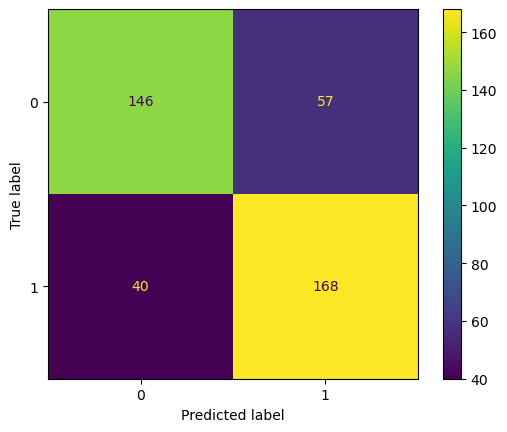

In [320]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

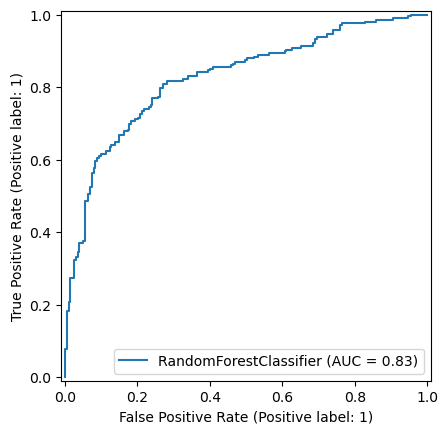

In [321]:
RocCurveDisplay.from_estimator(best_rf, X_test_transformed, y_test)

In [322]:
accuracy_score(y_test, y_predicted)

0.7639902676399026

In [323]:
recall_score(y_test, y_predicted)

0.8076923076923077

In [324]:
precision_score(y_test, y_predicted)

0.7466666666666667

In [325]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PowerTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [326]:
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC

clf_xgb = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'cat')),
                            ('classifier', XGBClassifier(random_state = 42, enable_categorical = True))])

In [369]:
param_distribution = {
    'classifier__max_depth': [2, 3], 
    'classifier__min_child_weight': randint(10, 20), 
    'classifier__lambda': randint(1, 10), 
    'classifier__alpha': randint(1, 5),
    'classifier__learning_rate': loguniform(0.01, 1),
    'classifier__n_estimators': randint(400, 600),
    'classifier__subsample': loguniform(0.5, 0.6),
    'classifier__colsample_bytree': loguniform(0.5, 0.6),
    'classifier__gamma': randint(2, 4)
}

In [370]:
model_xgb = RandomizedSearchCV(clf_xgb, param_distributions = param_distribution, n_iter = 10, scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], refit = 'f1_weighted', n_jobs = -1, cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42), random_state = 42, error_score = 'raise')

In [371]:
model_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__alpha': <scipy.stats....0027DF402A660>, 'classifier__colsample_bytree': <scipy.stats....0027DF4029A90>, 'classifier__gamma': <scipy.stats....0027DF4028130>, 'classifier__lambda': <scipy.stats....0027DF402A120>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1_weighted'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so th

In [372]:
best_xgb = model_xgb.best_estimator_

In [373]:
y_scores = best_xgb.predict_proba(X_test)[:, 1]

accuracy:  0.7419175392670156
recall:  0.7391752577319587
precision:  0.7467747382640999


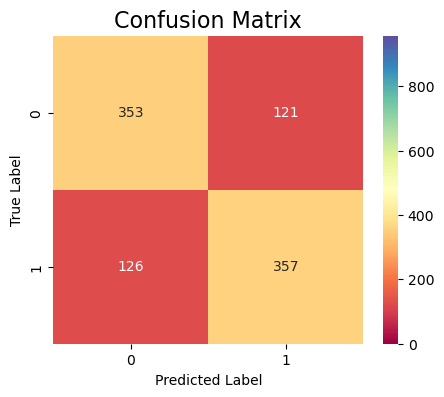

In [374]:
cv_cm(model_xgb, y_train)

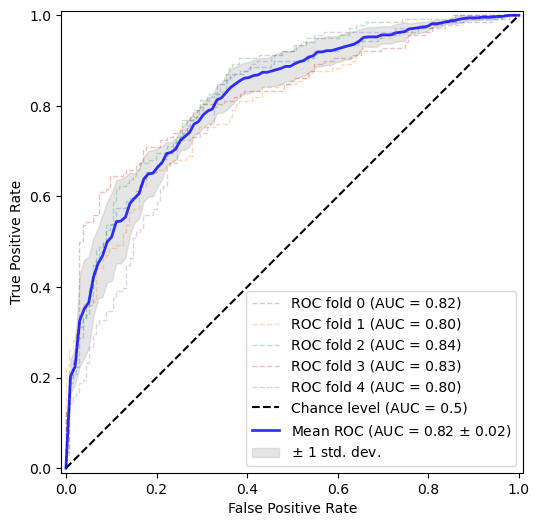

In [375]:
roc_cv(model_xgb)

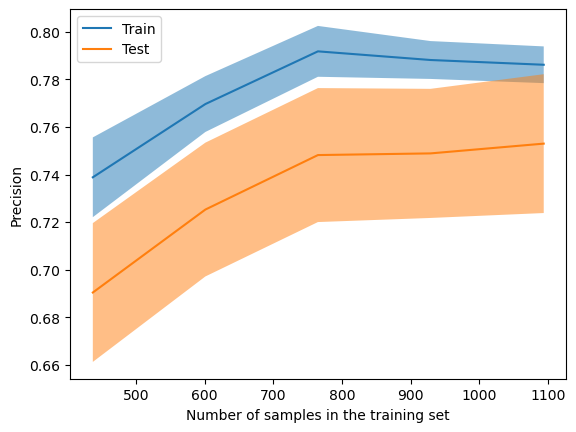

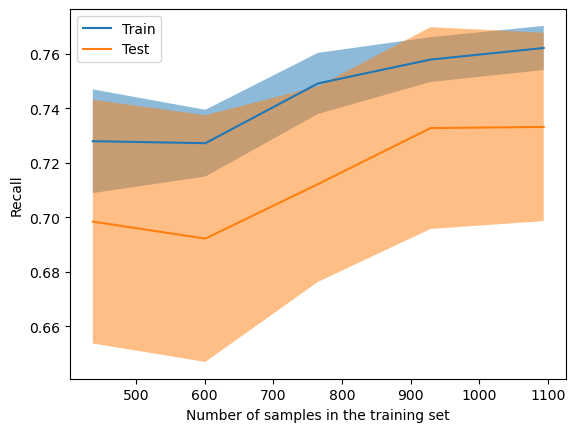

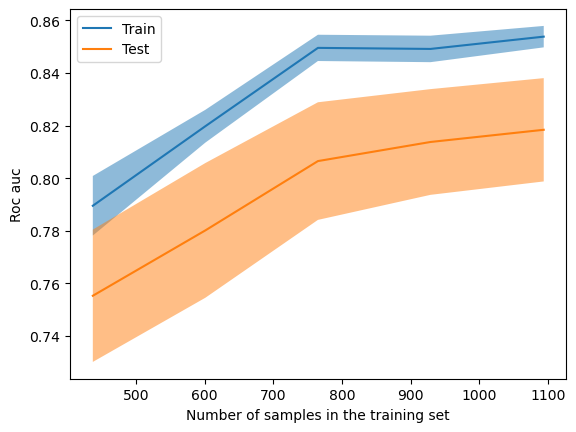

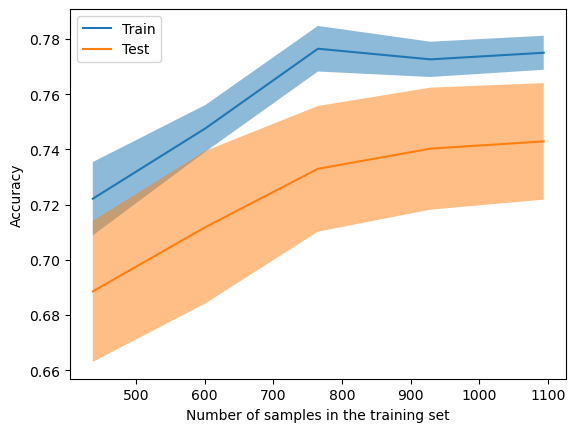

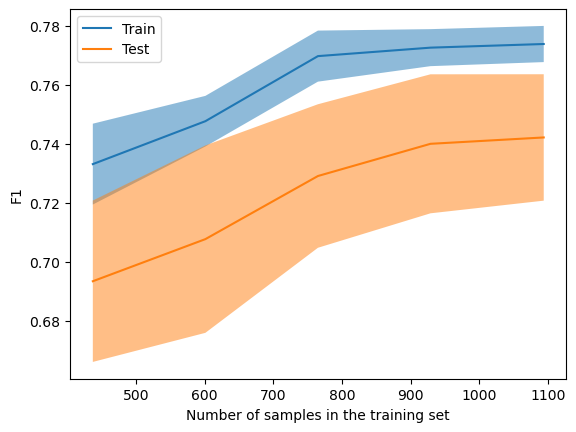

In [376]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_xgb, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

In [377]:
model_evaluation(best_xgb)

Mean precision: 0.7590455937928019
Standard deviation: 0.03559445414059807


Mean recall: 0.7392013345845063
Standard deviation: 0.030639065996259967


Mean roc_auc: 0.8207846662709615
Standard deviation: 0.019214104659262328


Mean accuracy: 0.7484024491323761
Standard deviation: 0.022655170747935872


Mean f1: 0.7480742875544621
Standard deviation: 0.01974194453473276




In [378]:
best_xgb = best_xgb.named_steps['classifier']

In [379]:
fitted_preprocessor = clf_xgb.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

In [380]:
feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [381]:
xgb_explainer = shap.TreeExplainer(best_xgb, X_train_transformed_df, model_output = 'probability')

In [382]:
xgb_shap_values_ohe = xgb_explainer(X_train_transformed_df)

In [383]:
xgb_shap_values_ohe = united_shapley(xgb_shap_values_ohe)

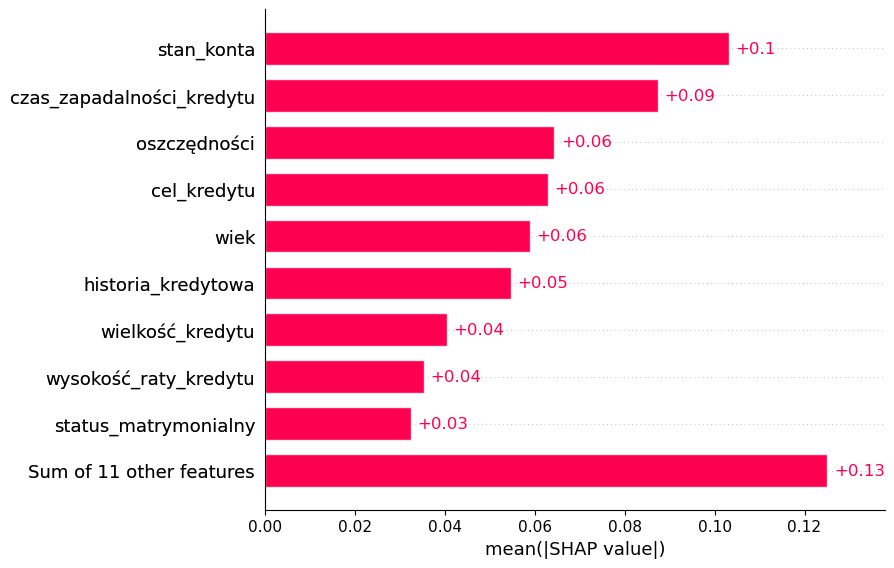

In [384]:
shap.plots.bar(xgb_shap_values_ohe)

In [385]:
X_train.iloc[1]

stan_konta                       1
czas_zapadalności_kredytu       38
historia_kredytowa               0
cel_kredytu                      5
wielkość_kredytu              5699
oszczędności                     1
czas_zatrudnienia                3
wysokość_raty_kredytu            3
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            38
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       3
praca                            2
liczba_osób_na_utrzymaniu        1
telefon                          1
cudzoziemiec                     2
Name: 414, dtype: object

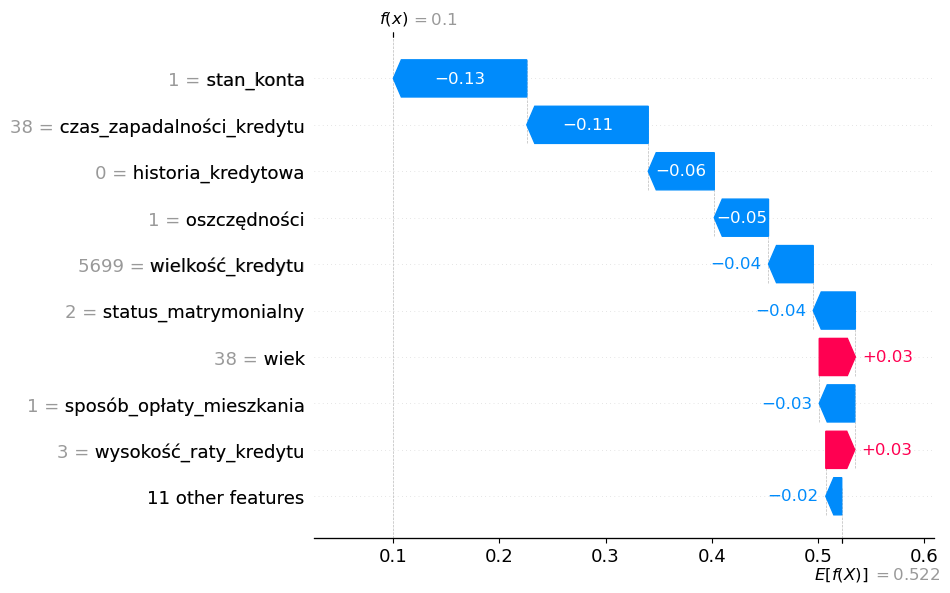

In [386]:
shap.plots.waterfall(xgb_shap_values_ohe[1], max_display = 10, show=True)

In [387]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      0
wielkość_kredytu              1207
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              2
wiek                            24
inne_kredyty                     3
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 896, dtype: object

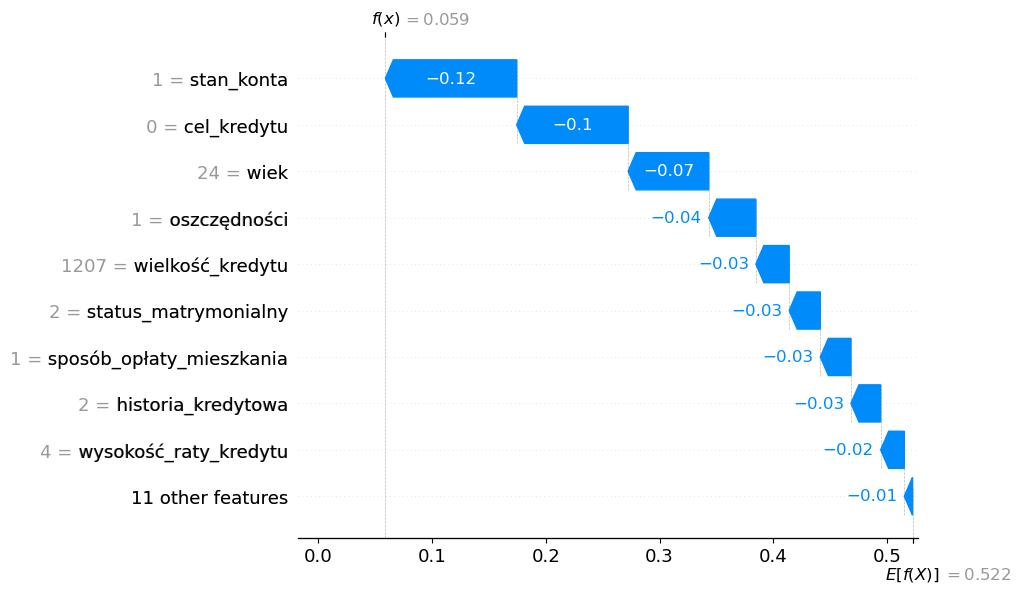

In [388]:
shap.plots.waterfall(xgb_shap_values_ohe[150], max_display = 10, show=True)

In [389]:
X_train.iloc[250]

stan_konta                       1
czas_zapadalności_kredytu       37
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              5633
oszczędności                     1
czas_zatrudnienia                1
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             2
najdroższa_własność              3
wiek                            36
inne_kredyty                     3
sposób_opłaty_mieszkania         3
liczba_kredytów_w_historii       2
praca                            4
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 318, dtype: object

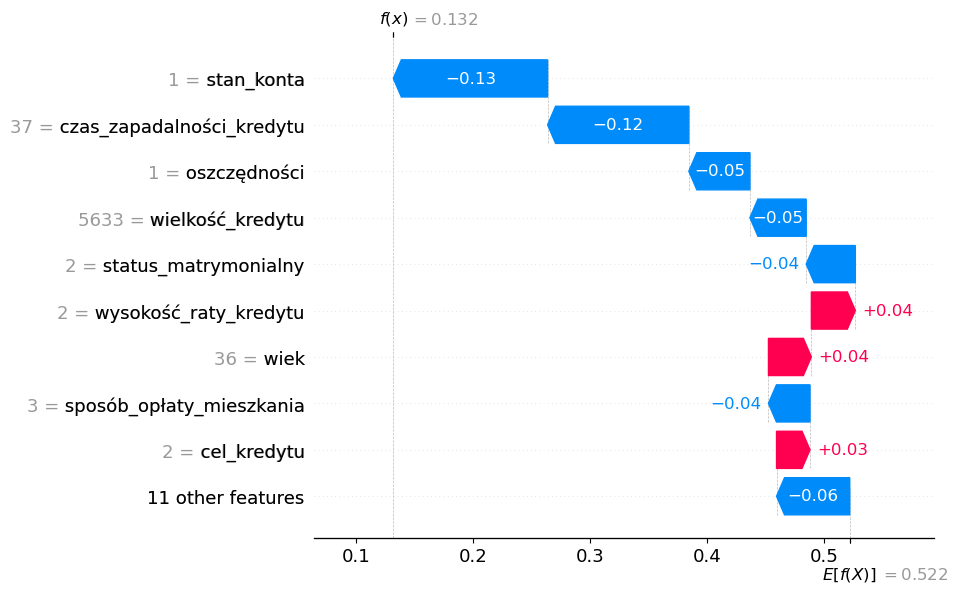

In [390]:
shap.plots.waterfall(xgb_shap_values_ohe[250], max_display = 10, show=True)

In [391]:
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.171259343624115

In [392]:
y_predicted = best_xgb.predict(X_test_transformed)

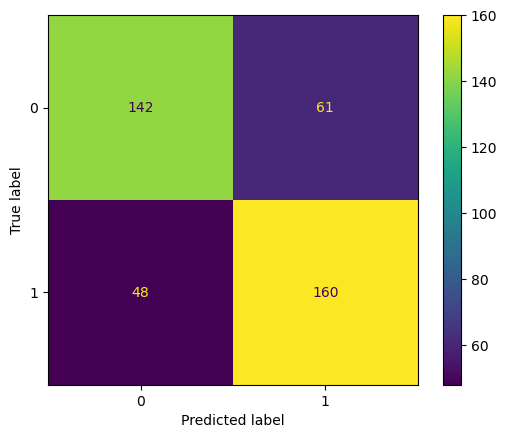

In [393]:
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

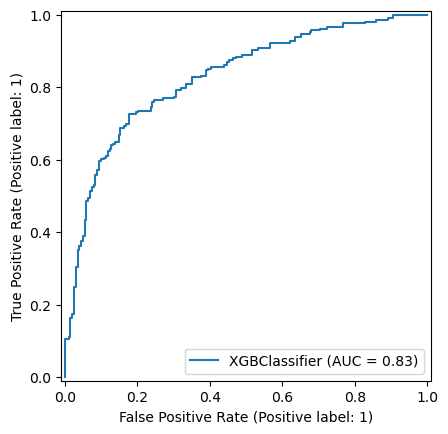

In [394]:
RocCurveDisplay.from_estimator(best_xgb, X_test_transformed, y_test)

In [395]:
accuracy_score(y_test, y_predicted)

0.7347931873479319

In [396]:
recall_score(y_test, y_predicted)

0.7692307692307693

In [397]:
precision_score(y_test, y_predicted)

0.7239819004524887